# WeatherAudit: grading weather forecasts against real station thermometers

**Track:** AI + Climate &nbsp;·&nbsp; **Starting point:** our own idea &nbsp;·&nbsp; prototype, not a weather service

Weather models are usually checked against other model products on a coarse grid. This notebook checks them against **real thermometers** instead: three public weather stations (Quzhou and Shanghai in China, Osaka in Japan). It answers four questions.

1. How far off is the forecast daily maximum temperature at each station?
2. How much of that error can be removed, and does machine learning beat a one-line rule?
3. Can we give an honest 80% range around the corrected forecast?
4. Does any of this help with two decisions: a heat alert and carrying an umbrella?

Answering question 2 turned up something we had not gone looking for: a *static* correction makes the forecast **worse**, because the thing we were calibrating against moved. At Quzhou the forecast ran about 1.2 °C cold during training and 1.7 °C warm during the test window. So the notebook asks a fifth question, and it is the one we think is new:

5. **When a bias like that jumps, which source actually changed — the thermometer, the forecast, or the reanalysis?** Section 3 answers this with a three-way cross-examination and scores it blind against NOAA's own provenance flags: right on 3 of 4 stations, no wrong labels, one miss caused by a gap in the station record.

**How to read this notebook.** All outputs are saved, so nothing has to be run. To re-run it, use *Runtime → Run all*. With `cache.zip` next to the notebook (it is in the repository; on Colab, upload it to the Files panel first) the run takes about a minute and reproduces the numbers (gradient-boosting figures can move by a few hundredths of a degree with a different scikit-learn version; nothing else changes). Without it, the same data is downloaded again from the public APIs, which is slower and may give slightly different numbers if the archives have been revised.

In [1]:
# -*- coding: utf-8 -*-
"""
WeatherAudit
Grade archived weather-model forecasts against real weather-station thermometers
(NOAA GHCN-Daily) in three cities, then ask how much of the error can be removed.

  * strict time split: the last 305 calendar days are the test window;
    every feature only uses station readings that are at least 8 days old,
  * fair baselines: fixed offset, monthly offset, rolling 7/30-day bias, gradient boosting,
    compared with a paired moving-block bootstrap (95% intervals),
  * a bias-drift timeline that explains why static corrections fail,
  * prediction intervals: static split-conformal vs rolling conformal,
  * a lead-time check on forecasts that were really issued 1-2 days ahead,
  * heat-alert and umbrella decisions, multi-model benchmark, station climate context,
  * a figure set + an HTML card that replays one past day.

Run:  python weatheraudit.py   (the notebook WeatherAudit.ipynb contains the same code, cell by cell)
"""
import io, hashlib, json, os, pickle, time, warnings
from datetime import date, timedelta
from pathlib import Path

# keep the numeric libraries to a few threads (stable on small machines)
os.environ.setdefault("OMP_NUM_THREADS", "2")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "2")
os.environ.setdefault("MKL_NUM_THREADS", "2")

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests

from sklearn.ensemble import HistGradientBoostingClassifier, HistGradientBoostingRegressor
from sklearn.metrics import brier_score_loss, roc_auc_score
from scipy.stats import linregress

try:
    from IPython.display import display, HTML
except ImportError:
    display = print
    HTML = lambda s: s

warnings.filterwarnings("ignore", category=FutureWarning)   # pandas 2.x concat notice, harmless here
pd.set_option("display.width", 250, "display.max_columns", None, "display.max_colwidth", 60)
rng = np.random.default_rng(42)

# ---------------------------------------------------------------------------
# global plot style
# ---------------------------------------------------------------------------
NAVY, TEAL, AMBER, RED, GRAY, BLUE = "#1F3864", "#2a9d8f", "#e9c46a", "#a61b1b", "#8a8a8a", "#457b9d"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#cccccc", "axes.grid": True, "grid.color": "#e9e9e9",
    "grid.linewidth": 0.7, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.titlecolor": NAVY, "axes.labelcolor": "#333333",
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

In [2]:
# -----------------------------------------------------------------------------
# Cell 1 — configuration
# -----------------------------------------------------------------------------
STATIONS = {
    # name: (GHCN-Daily station id, latitude, longitude)
    # Quzhou is the nearest GHCN station with recent data to the author's home (~114 km away)
    "Quzhou": ("CHM00058633", 28.97, 118.87),
    "Shanghai": ("CHM00058362", 31.40, 121.47),
    "Osaka": ("JAM00047772", 34.68, 135.52),
}
PRIMARY = "Quzhou"
# Freeze the last day of each audit so that a re-run reproduces the write-up numbers.
# (Stations keep reporting; set PIN_END = {} to audit up to the newest reading instead.)
PIN_END = {"Quzhou": "2026-09-22", "Shanghai": "2026-09-22", "Osaka": "2026-11-06"}
TEST_DAYS = 305          # the last 305 calendar days are the test window, never used for training
N_EST = 400              # max boosting iterations (early stopping usually ends sooner)
C_UMB = 1                # cost of carrying an umbrella for nothing
C_RAIN = 6               # cost of getting soaked (6x the umbrella cost)
RAIN_MM = 1.0            # a day with >= 1 mm of precipitation counts as a "rain day"
N_JOBS = 4
CONF_LEVEL = 0.80        # target coverage of the prediction interval
CONF_CAL_FRAC = 0.30     # static split-conformal: last 30% of training used for calibration
TREND_MIN_YEARS = 20     # minimum complete years before we fit a climate trend
MODELS = ["ecmwf_ifs025", "gfs_seamless", "icon_seamless"]
MODEL_LABEL = {"ecmwf_ifs025": "ECMWF IFS", "gfs_seamless": "GFS", "icon_seamless": "ICON"}
MM_NAME = {"mm_ecmwf": "ECMWF IFS", "mm_gfs": "GFS", "mm_icon": "ICON"}

CACHE_DIR = Path("cache")
# The repository ships cache.zip (the exact API responses behind the write-up numbers).
# With it the notebook reproduces every number in about a minute; without it everything is
# downloaded again from the public APIs (slow: the free tier is rate-limited).
CACHE_URL = ""           # optional: direct link to cache.zip (used when the file is not next to the notebook)
if not CACHE_DIR.exists():
    import zipfile
    if not Path("cache.zip").exists() and CACHE_URL:
        try:
            Path("cache.zip").write_bytes(requests.get(CACHE_URL, timeout=120).content)
        except Exception as e:
            print("could not download cache.zip, will use the live APIs instead:", repr(e)[:120])
    if Path("cache.zip").exists():
        with zipfile.ZipFile("cache.zip") as zf:
            zf.extractall(CACHE_DIR)
        print("using cached API responses from cache.zip")
CACHE_DIR.mkdir(exist_ok=True)
STATION_BASE = "https://noaa-ghcn-pds.s3.amazonaws.com/csv/by_station"
OM_FORECAST = "https://historical-forecast-api.open-meteo.com/v1/forecast"
OM_ARCHIVE = "https://archive-api.open-meteo.com/v1/archive"
OM_LIVE = "https://api.open-meteo.com/v1/forecast"
OM_DAILY = ("temperature_2m_max,temperature_2m_min,precipitation_probability_max,relative_humidity_2m_mean")
AR_DAILY = ("temperature_2m_max,precipitation_sum")

using cached API responses from cache.zip


## 1. Data

| What | Source | Used as |
|---|---|---|
| Station readings (daily max/min temperature, precipitation) | NOAA GHCN-Daily, public CSV per station | **the truth** |
| Archived model forecasts (default model, plus ECMWF IFS, GFS, ICON) | Open-Meteo Historical Forecast API | the thing being graded |
| Forecasts issued 1 and 2 days earlier | Open-Meteo Previous Runs API | lead-time check |
| ERA5 reanalysis on the model grid | Open-Meteo Archive API | context only |

Two facts about the data shape the whole design.

* **Stations have gaps.** We keep only days on which the station really reported. The Chinese stations rarely report precipitation, so the rain part uses far fewer days than the temperature part (Table 1).
* **A forecast compared with a reanalysis looks perfect.** Our first version used ERA5 as the truth and the forecast looked almost perfect. That was meaningless: both products come from the same kind of model on the same grid. At the two Chinese stations the forecast differs from ERA5 by about 0.1 °C but from the station thermometer by 1 to 2 °C. This is why the project uses stations.

In [3]:
def _get(url, params):
    """Cached GET with retries + backoff."""
    key = url + "?" + "&".join(f"{k}={v}" for k, v in sorted(params.items()))
    f = CACHE_DIR / (hashlib.md5(key.encode("utf-8")).hexdigest() + ".pkl")
    if f.exists():
        with open(f, "rb") as fh:
            return pickle.load(fh)
    for n in range(6):
        try:
            r = requests.get(url, params=params, timeout=300)
            if r.status_code == 200:
                data = r.json()
                with open(f, "wb") as fh:
                    pickle.dump(data, fh)
                return data
            print(f"  HTTP {r.status_code} {r.text[:160]} retry {n}")
            if r.status_code == 429:          # free-tier rate limit: wait for the next minute
                time.sleep(62)
        except Exception as e:
            print(f"  retry {n}: {type(e).__name__}")
        time.sleep(4 * (n + 1))
    raise RuntimeError("fetch failed: " + url)


def fetch_om(base, lat, lon, start, end, daily, models=None):
    """Fetch a daily endpoint year-by-year. If `models` given, return the
    per-model temperature columns as well."""
    frames = []
    for y in range(start.year, end.year + 1):
        ye = min(f"{y}-12-31", end.strftime("%Y-%m-%d"))
        p = dict(latitude=lat, longitude=lon, daily=daily,
                 timezone="Asia/Shanghai", start_date=f"{y}-01-01", end_date=ye)
        if models:
            p["models"] = ",".join(models)
        data = _get(base, p)
        if "daily" in data and data["daily"]:
            d = pd.DataFrame(data["daily"])
            d["time"] = pd.to_datetime(d["time"])
            frames.append(d)
    if not frames:
        return pd.DataFrame()
    out = pd.concat(frames, ignore_index=True)
    out = out.drop_duplicates(subset="time").sort_values("time").reset_index(drop=True)
    return out[(out.time >= pd.Timestamp(start)) & (out.time <= pd.Timestamp(end))].reset_index(drop=True)


def fetch_station(sid):
    """GHCN daily CSV -> full-record TMAX/TMIN/PRCP series (tenths of a unit), plus
    the TMAX provenance flags.

    The source flag (S_FLAG) and measurement flag (M_FLAG) say where each reading came
    from and how it was derived. Cell "crossexam" uses a change of those flags as a
    blind answer key, so they are cached alongside the values.
    Cached as a small gzip CSV so the cache works with any pandas version."""
    f = CACHE_DIR / f"station_{sid}_v2.csv.gz"
    if f.exists():
        c = pd.read_csv(f, parse_dates=["date"]).set_index("date")
        out = {el: c[el].dropna() for el in ["TMAX", "TMIN", "PRCP"]}
        out["TMAX_FLAG"] = c["TMAX_FLAG"].fillna("").astype(str) if "TMAX_FLAG" in c else pd.Series(dtype=str)
        return out
    r = None
    for n in range(4):
        try:
            r = requests.get(f"{STATION_BASE}/{sid}.csv", timeout=300)
            if r.status_code == 200:
                break
        except Exception as e:
            print(f"  station retry {n}: {type(e).__name__}")
            time.sleep(4 * (n + 1))
    if r is None or r.status_code != 200:
        raise RuntimeError(f"station fetch failed: {sid}")
    s = pd.read_csv(io.StringIO(r.content.decode("utf-8")), dtype={"DATE": str}, low_memory=False)
    s["date"] = pd.to_datetime(s["DATE"], format="%Y%m%d", errors="coerce")
    s = s[(s.Q_FLAG.fillna("") == "") & s.date.notna()].copy()
    s = s.set_index("date")
    out = {}
    for el in ["TMAX", "TMIN", "PRCP"]:
        sub = s[s.ELEMENT == el]["DATA_VALUE"].astype(float)
        out[el] = (sub / 10.0).groupby(level=0).last()
    tm = s[s.ELEMENT == "TMAX"]
    flag = (tm.S_FLAG.fillna("").astype(str) + "|" + tm.M_FLAG.fillna("").astype(str))
    out["TMAX_FLAG"] = flag.groupby(level=0).last()
    frame = pd.DataFrame({k: v for k, v in out.items()})
    frame.rename_axis("date").to_csv(f, compression="gzip")
    return out

In [4]:
def build_frames(name, sid, lat, lon, end):
    """Fetch all sources, return (temp_df, rain_df, meta)."""
    station = fetch_station(sid)
    last_tmax = station["TMAX"].index.max()
    if end is None:
        end = last_tmax
    end = min(end, last_tmax)
    start = end - timedelta(days=4 * 366)          # look-back window: up to 4 years (stations have gaps)
    test_start = end - timedelta(days=TEST_DAYS)

    print(f"[{name}] station {sid}  last TMAX {last_tmax.date()}  window {start.date()} -> {end.date()}")
    om = fetch_om(OM_FORECAST, lat, lon, start, end, OM_DAILY)
    grid = fetch_om(OM_ARCHIVE, lat, lon, start, end, AR_DAILY)

    df = pd.DataFrame({"date": pd.date_range(start, end, freq="D")})
    om2 = om.rename(columns={"time": "date"})[["date", "temperature_2m_max", "temperature_2m_min", "precipitation_probability_max", "relative_humidity_2m_mean"]]
    gr2 = grid.rename(columns={"time": "date"})[["date", "temperature_2m_max", "precipitation_sum"]]
    df = df.merge(om2, on="date", how="left").merge(gr2, on="date", how="left", suffixes=("", "_grid"))
    df = df.rename(columns={
        "temperature_2m_max": "fc_tmax", "temperature_2m_min": "fc_tmin",
        "precipitation_probability_max": "fc_prob", "relative_humidity_2m_mean": "fc_hum",
        "temperature_2m_max_grid": "g_tmax", "precipitation_sum": "g_prcp",
    })
    for el, col in [("TMAX", "s_tmax"), ("TMIN", "s_tmin"), ("PRCP", "s_prcp")]:
        df[col] = df.date.map(station[el])

    df = df.set_index("date")
    err = df.s_tmax - df.fc_tmax
    df["err"] = err
    df["doy"] = df.index.day_of_year
    df["doy_sin"] = np.sin(2 * np.pi * df.doy / 365.25)
    df["doy_cos"] = np.cos(2 * np.pi * df.doy / 365.25)
    df["fc_wet"] = (df.fc_prob >= 50).astype(float)
    df["bias_7"] = err.shift(8).rolling(7, min_periods=3).mean()
    df["bias_30"] = err.shift(8).rolling(30, min_periods=5).mean()
    df["lag1_err"] = err.shift(8)
    rain_true = (df.s_prcp >= RAIN_MM).astype(float)
    df["wet_hist_30"] = rain_true.shift(8).rolling(30, min_periods=5).mean()
    df["fc_wet_hist_30"] = df.fc_wet.shift(8).rolling(30, min_periods=5).mean()
    df = df.reset_index()

    temp = df[df.fc_tmax.notna() & df.s_tmax.notna()].copy()
    rain = df[df.fc_prob.notna() & df.s_prcp.notna()].copy()
    meta = dict(start=start, end=end, test_start=test_start)
    return temp, rain, meta

## 2. Method

**Time split.** For each station the last 305 calendar days are the test window. Everything before it, back to late 2022 where the station has data, is training (Table 1). Nothing from the test window is used to fit or tune anything.

**No peeking.** Station readings reach the public archive a few days late. So every feature that looks at past errors only uses readings that are **at least 8 days old** on the day of the forecast. The same rule applies to every baseline.

**Methods compared for temperature**, from simplest to most complex:

| Method | What it does |
|---|---|
| Default forecast | use the model forecast as it is |
| Fixed offset | add the average training-period error |
| Monthly offset | add the average training-period error of that calendar month |
| Rolling 7-day / 30-day bias | add the forecast's average error over a 7 / 30-day window that ends 8 days earlier |
| Gradient boosting | `HistGradientBoostingRegressor` predicts the error from the forecast values, season and recent errors |

**How we decide who wins.** We report mean absolute error (MAE) and a 95% interval for the difference between two methods, from a paired moving-block bootstrap (7-day blocks, 4000 resamples). If the interval contains zero we call it a tie. Because early stopping makes gradient boosting depend on a random seed, we also refit it with 10 seeds.

**Rain.** A `HistGradientBoostingClassifier` turns the forecast rain probability into a new probability of a rain day (at least 1 mm at the station). We score it with the Brier score and with an umbrella cost: carrying one for nothing costs 1, getting soaked costs 6.

**Ranges.** A static split-conformal interval (calibrated once, on the end of the training period) is compared with a rolling conformal interval (recalibrated every day on the last 90 days).

In [5]:
FEATURES_T = ["doy_sin", "doy_cos", "fc_tmax", "fc_tmin", "fc_prob", "fc_wet", "fc_hum", "bias_7", "bias_30", "lag1_err"]
FEATURES_R = ["doy_sin", "doy_cos", "fc_prob", "fc_wet", "fc_hum", "wet_hist_30", "fc_wet_hist_30", "bias_7", "bias_30"]


def umbrella_cost(prob, rain, th):
    dec = prob >= th
    return float(((dec & ~rain) * C_UMB + (~dec & rain) * C_RAIN).sum() * 1000.0 / len(prob))


def pick_threshold(prob, rain):
    best, best_c = None, np.inf
    for th in np.arange(0.02, 0.99, 0.02):
        c = umbrella_cost(prob, rain, th)
        if c < best_c:
            best_c, best = c, th
    return best, best_c


def usable(X, thr=2):
    return [c for c in X.columns if X[c].nunique() >= thr]


def make_reg(**kw):
    base = dict(max_iter=N_EST, learning_rate=0.05, max_depth=4,
                min_samples_leaf=10, random_state=42, validation_fraction=0.1,
                early_stopping=True, n_iter_no_change=20)
    base.update(kw)
    return HistGradientBoostingRegressor(**base)


def audit_city(name, sid, lat, lon, end=None):
    temp, rain, meta = build_frames(name, sid, lat, lon, end)
    ts = meta["test_start"]
    tr = temp[temp.date < ts]
    te = temp[temp.date >= ts]
    ft = usable(tr[FEATURES_T])
    month_bias = tr.groupby(tr.date.dt.month)["err"].mean()
    te = te.copy()
    te["month_bias"] = te.date.dt.month.map(month_bias)
    lin_pred = te.fc_tmax + te.month_bias

    m = make_reg(loss="absolute_error")
    m.fit(tr[ft], tr["err"])
    gb_pred = te.fc_tmax + m.predict(te[ft])

    HOT_TH = float(tr.s_tmax.quantile(0.90))
    te = te.copy()
    te["hot"] = te.s_tmax >= HOT_TH
    hot = te[te.hot]

    raw_mae = float((te.fc_tmax - te.s_tmax).abs().mean())
    lin_mae = float((lin_pred - te.s_tmax).abs().mean())
    gb_mae = float((gb_pred - te.s_tmax).abs().mean())
    raw_hot_mae = float((hot.fc_tmax - hot.s_tmax).abs().mean())
    gb_hot_mae = float((gb_pred[hot.index] - hot.s_tmax).abs().mean())
    gb_better = float((((gb_pred - te.s_tmax).abs()) < (te.fc_tmax - te.s_tmax).abs()).mean())

    raw_alert = te.fc_tmax >= HOT_TH
    gb_alert = gb_pred >= HOT_TH
    heat = dict(th=round(HOT_TH, 1), n_days=int(te.hot.sum()),
                raw_caught=int((raw_alert & te.hot).sum()), gb_caught=int((gb_alert & te.hot).sum()),
                raw_false=int((raw_alert & ~te.hot).sum()), gb_false=int((gb_alert & ~te.hot).sum()))

    d = te[te.g_tmax.notna() & te.s_tmax.notna()]
    decomp = dict(
        total=float((d.fc_tmax - d.s_tmax).abs().mean()),
        model_grid=float((d.fc_tmax - d.g_tmax).abs().mean()),
        grid_to_station=float((d.g_tmax - d.s_tmax).abs().mean()))

    rr = rain[rain.date < ts]
    re_ = rain[rain.date >= ts].copy()
    re_["y"] = (re_.s_prcp >= RAIN_MM).astype(int)
    rr = rr.copy(); rr["y"] = (rr.s_prcp >= RAIN_MM).astype(int)

    cm = HistGradientBoostingClassifier(loss="log_loss", max_iter=N_EST, learning_rate=0.05,
                                        max_depth=4, min_samples_leaf=20, random_state=42,
                                        validation_fraction=0.1, early_stopping=True, n_iter_no_change=20)
    fr = usable(rr[FEATURES_R])
    cm.fit(rr[fr], rr["y"])
    p_raw = re_.fc_prob.values / 100.0
    p_gb = cm.predict_proba(re_[fr])[:, 1]
    y = re_.y.values

    base_rate = float(rr.y.mean())                      # climatological rain frequency (train only)
    brier_base = float(brier_score_loss(y, np.full(len(y), base_rate)))
    brier_raw = float(brier_score_loss(y, p_raw))
    brier_gb = float(brier_score_loss(y, p_gb))
    auc_raw = float(roc_auc_score(y, p_raw))
    auc_gb = float(roc_auc_score(y, p_gb))
    th_raw, _ = pick_threshold(rr.fc_prob.values / 100.0, rr.y.values)
    th_gb, _ = pick_threshold(cm.predict_proba(rr[fr])[:, 1], rr.y.values)
    cost_always = 1000.0
    cost_never = float(y.mean() * C_RAIN * 1000)
    cost_raw = umbrella_cost(p_raw, y.astype(bool), th_raw)
    cost_gb = umbrella_cost(p_gb, y.astype(bool), th_gb)
    cost_gb_cal = umbrella_cost(p_gb, y.astype(bool), C_UMB / (C_UMB + C_RAIN))

    res = dict(
        name=name, sid=sid,
        train_days=int(len(tr)), temp_test_days=int(len(te)),
        rain_train_days=int(len(rr)), rain_test_days=int(len(re_)),
        temp_train_span=[str(tr.date.min().date()), str(tr.date.max().date())],
        temp_test_span=[str(te.date.min().date()), str(te.date.max().date())],
        rain_test_span=[str(re_.date.min().date()), str(re_.date.max().date())],
        raw_mae=round(raw_mae, 2), lin_mae=round(lin_mae, 2), gb_mae=round(gb_mae, 2),
        gb_better=round(gb_better, 3), raw_hot_mae=round(raw_hot_mae, 2), gb_hot_mae=round(gb_hot_mae, 2),
        heat=heat, decomp={k: round(v, 2) for k, v in decomp.items()},
        brier_base=round(brier_base, 4), brier_raw=round(brier_raw, 4), brier_gb=round(brier_gb, 4),
        auc_raw=round(auc_raw, 3), auc_gb=round(auc_gb, 3),
        th_raw=round(float(th_raw), 2), th_gb=round(float(th_gb), 2),
        cost_always=cost_always, cost_never=round(cost_never, 0),
        cost_raw=round(cost_raw, 0), cost_gb=round(cost_gb, 0), cost_gb_cal=round(cost_gb_cal, 0),
        rain_rate=round(float(y.mean()), 3),
    )
    ctx = dict(temp=te, rain=re_, tr=tr, model=m, cmodel=cm, HOT_TH=HOT_TH,
               gb_pred=gb_pred, p_gb=p_gb, p_raw=p_raw, th_gb=th_gb, th_raw=th_raw,
               cost_raw=cost_raw, cost_gb=cost_gb, cost_gb_cal=cost_gb_cal,
               ft=ft, fr=fr, ts=ts, lat=lat, lon=lon, meta=meta)
    return res, ctx

In [6]:
def koppen(tmax, tmin, prcp):
    """Classify climate from full station record (Koeppen)."""
    tmean = ((tmax + tmin) / 2.0)
    mt = tmean.groupby(tmean.index.month).mean()          # mean monthly temperature
    mp = prcp.resample("ME").sum()                        # monthly total precip
    mp = mp.groupby(mp.index.month).mean()                # mean monthly total
    t_ann = float(tmean.mean())
    t_warm = float(mt.max()); t_cold = float(mt.min())
    p_ann = float(mp.sum())                               # mean annual total precip

    if t_cold >= 18:
        grp = "A"
    elif t_ann >= 10 and 0 < t_cold < 18:
        grp = "C"
    elif t_cold <= 0 and t_warm > 10:
        grp = "D"
    elif t_ann < 10 and t_warm <= 10:
        grp = "E"
    else:
        grp = "B"   # dry; not refined here

    # precipitation seasonality (C/D): w = dry winter, s = dry summer, f = no dry season
    p_summ = float(mp[[4, 5, 6, 7, 8, 9]].sum())
    p_wint = float(mp[[10, 11, 12, 1, 2, 3]].sum())
    p_min = float(mp.min()); p_max = float(mp.max())
    sub = "f"
    if p_wint / max(p_ann, 1e-6) < 0.10:
        sub = "w"
    elif p_summ / max(p_ann, 1e-6) < 0.10:
        sub = "s"
    # temperature subtype
    if grp in ("C", "D"):
        if t_warm >= 22:
            sub2 = "a"
        elif t_cold >= -38 and (mt >= 10).sum() >= 4:
            sub2 = "b"
        elif (mt >= 10).sum() >= 1 and (mt >= 10).sum() < 4:
            sub2 = "c"
        else:
            sub2 = "d"
    else:
        sub2 = ""
    return dict(grp=grp, sub=sub, sub2=sub2, code=f"{grp}{sub}{sub2}",
                t_ann=round(t_ann, 1), t_warm=round(t_warm, 1), t_cold=round(t_cold, 1),
                p_ann=round(p_ann, 0))


def _annual_mean(series):
    """Annual mean of a series, keeping only complete years (>= 350 days)."""
    ann = series.resample("YE").mean()
    cnt = series.resample("YE").count()
    return ann[cnt >= 350].dropna()


def climate_trend(series):
    """Annual mean linear trend, degC per decade. We trend annual mean Tmax —
    the exact variable WeatherAudit corrects — because Tmin records are sparse
    for some stations (e.g. Osaka has only 1 complete Tmin year)."""
    ann = _annual_mean(series)
    x = ann.index.year.values.astype(float)
    y = ann.values
    if len(x) < TREND_MIN_YEARS:
        return dict(years=int(len(x)), slope=None)
    slope, intercept, r, p, se = linregress(x, y)
    return dict(years=int(len(x)), first_year=int(x[0]), last_year=int(x[-1]),
                slope_decade=round(slope * 10, 3), r=round(r, 2),
                p=float(p), change_total=round(slope * (x[-1] - x[0]), 2))


def station_climate(sid):
    st = fetch_station(sid)
    k = koppen(st["TMAX"], st["TMIN"], st["PRCP"])
    tr = climate_trend(st["TMAX"])
    return dict(koppen=k, trend_tmax=tr)

In [7]:
def multi_model_audit(name, sid, lat, lon, meta, te):
    """Benchmark ECMWF / GFS / ICON against the station on the test period and
    compute a multi-model mean + model spread."""
    start, end = meta["start"], meta["end"]
    mm = fetch_om(OM_FORECAST, lat, lon, start, end, "temperature_2m_max", models=MODELS)
    if mm.empty:
        return dict(available=False)
    colmap = {"temperature_2m_max_ecmwf_ifs025": "mm_ecmwf",
              "temperature_2m_max_gfs_seamless": "mm_gfs",
              "temperature_2m_max_icon_seamless": "mm_icon"}
    mm = mm.rename(columns={k: v for k, v in colmap.items() if k in mm.columns})
    cols = [c for c in ("mm_ecmwf", "mm_gfs", "mm_icon") if c in mm.columns]
    mm["date"] = mm["time"]
    mdf = mm[["date"] + cols].merge(te[["date", "s_tmax", "fc_tmax"]], on="date", how="right")
    mte = mdf[mdf.date >= meta["test_start"]].copy()

    per_model = {}
    for c in cols:
        sub = mte[mte[c].notna() & mte.s_tmax.notna()]
        if len(sub) >= 30:
            per_model[MM_NAME.get(c, c)] = dict(
                n=int(len(sub)), mae=round(float((sub[c] - sub.s_tmax).abs().mean()), 2))

    mte["consensus"] = mte[cols].mean(axis=1, skipna=True)
    mte["spread"] = mte[cols].std(axis=1, skipna=True)
    mte["n_models"] = mte[cols].notna().sum(axis=1)
    ok = mte[mte.consensus.notna() & mte.s_tmax.notna()]
    # single best available model vs consensus
    best_single = None
    for c in cols:
        sub = ok[ok[c].notna()]
        if len(sub):
            mae = float((sub[c] - sub.s_tmax).abs().mean())
            if best_single is None or mae < best_single[1]:
                best_single = (c, mae)
    cons_mae = float((ok.consensus - ok.s_tmax).abs().mean()) if len(ok) else None
    raw_mae_mm = float((ok.fc_tmax - ok.s_tmax).abs().mean()) if len(ok) else None

    # merge spread onto test for the credibility module
    te = te.merge(mte[["date", "consensus", "spread", "n_models"]], on="date", how="left")

    return dict(available=True, per_model={k: v for k, v in per_model.items()},
                n_test=int(len(ok)),
                consensus_mae=round(cons_mae, 2) if cons_mae is not None else None,
                best_single=MM_NAME.get(best_single[0], best_single[0]) if best_single else None,
                best_single_mae=round(best_single[1], 2) if best_single else None,
                raw_mae=round(raw_mae_mm, 2) if raw_mae_mm is not None else None,
                spread_mean=round(float(ok.spread.mean()), 2) if len(ok) else None), te

In [8]:
def conformal_intervals(ctx, te, level=CONF_LEVEL):
    """Split-conformal 80% interval around the corrected temperature forecast."""
    tr = ctx["tr"]
    ft = ctx["ft"]
    cut = tr.date.quantile(1 - CONF_CAL_FRAC)
    fit = tr[tr.date < cut]
    cal = tr[tr.date >= cut]
    m = make_reg(loss="absolute_error")
    m.fit(fit[ft], fit["err"])
    cal_resid = (cal["err"] - m.predict(cal[ft])).abs().values
    q = float(np.quantile(cal_resid, level))
    te = te.copy()
    te["cf_pred"] = te.fc_tmax + m.predict(te[ft])
    te["cf_lo"] = te.cf_pred - q
    te["cf_hi"] = te.cf_pred + q
    cov = float(((te.s_tmax >= te.cf_lo) & (te.s_tmax <= te.cf_hi)).mean())
    width = float((te.cf_hi - te.cf_lo).mean())

    # quantile-regression interval (CQR-style, no conformal step)
    lo_m = make_reg(loss="quantile", quantile=(1 - level) / 2)
    hi_m = make_reg(loss="quantile", quantile=(1 + level) / 2)
    lo_m.fit(tr[ft], tr["err"])
    hi_m.fit(tr[ft], tr["err"])
    te["qr_lo"] = te.fc_tmax + lo_m.predict(te[ft])
    te["qr_hi"] = te.fc_tmax + hi_m.predict(te[ft])
    qr_cov = float(((te.s_tmax >= te.qr_lo) & (te.s_tmax <= te.qr_hi)).mean())
    qr_width = float((te.qr_hi - te.qr_lo).mean())

    return dict(target=level, split_conformal=dict(coverage=round(cov, 3), width=round(width, 2)),
                quantile=dict(coverage=round(qr_cov, 3), width=round(qr_width, 2))), te


def credibility(te):
    """A 0-100 baseline trust score, then audited: do high-trust days actually
    have smaller error? Combines model agreement + recent forecast reliability."""
    t = te.copy()
    agree = 1.0 / (1.0 + t.spread.fillna(t.spread.median()))          # model agreement
    reliab = 1.0 / (1.0 + t.bias_30.abs().fillna(t.bias_30.abs().median()))  # recent reliability
    t["trust"] = 100.0 * (0.5 * agree + 0.5 * reliab)
    t["abs_err"] = (t.fc_tmax - t.s_tmax).abs()
    # terciles by trust
    q1, q2 = t.trust.quantile(0.33), t.trust.quantile(0.66)
    def lvl(v):
        return "high" if v >= q2 else ("low" if v < q1 else "mid")
    t["trust_lvl"] = t.trust.map(lvl)
    g = t.groupby("trust_lvl")["abs_err"].mean()
    bins = {k: round(float(g.get(k, np.nan)), 2) for k in ("low", "mid", "high")}
    return dict(bins=bins, monotonic=bool(bins["low"] >= bins["mid"] >= bins["high"]),
                n=dict(low=int((t.trust_lvl == "low").sum()), mid=int((t.trust_lvl == "mid").sum()),
                       high=int((t.trust_lvl == "high").sum()))), t

In [9]:
def smartbase_audit(name, sid, lat, lon, end=None):
    """Correct several base forecasts (default model / GFS / ICON / ECMWF / consensus)
    with the SAME no-leakage, full-calendar features as the core. Returns a raw ->
    corrected ladder. Headline: multi-model consensus + correction is the most robust."""
    station = fetch_station(sid)
    last_tmax = station["TMAX"].index.max()
    if end is None:
        end = last_tmax
    end = min(end, last_tmax)
    start = end - timedelta(days=4 * 366)
    ts = end - timedelta(days=TEST_DAYS)

    om = fetch_om(OM_FORECAST, lat, lon, start, end, OM_DAILY)
    mm = fetch_om(OM_FORECAST, lat, lon, start, end, "temperature_2m_max", models=MODELS)
    if mm.empty:
        return None
    colmap = {"temperature_2m_max_ecmwf_ifs025": "mm_ecmwf",
              "temperature_2m_max_gfs_seamless": "mm_gfs",
              "temperature_2m_max_icon_seamless": "mm_icon"}
    mm = mm.rename(columns={k: v for k, v in colmap.items() if k in mm.columns})
    cols = [c for c in ("mm_ecmwf", "mm_gfs", "mm_icon") if c in mm.columns]

    df = pd.DataFrame({"date": pd.date_range(start, end, freq="D")})
    om2 = om.rename(columns={"time": "date"})[["date", "temperature_2m_max", "temperature_2m_min",
                                               "precipitation_probability_max", "relative_humidity_2m_mean"]]
    mm2 = mm.rename(columns={"time": "date"})[["date"] + cols]
    df = df.merge(om2, on="date", how="left").merge(mm2, on="date", how="left")
    df = df.rename(columns={"temperature_2m_max": "fc_tmax", "temperature_2m_min": "fc_tmin",
                            "precipitation_probability_max": "fc_prob", "relative_humidity_2m_mean": "fc_hum"})
    df["s_tmax"] = df.date.map(station["TMAX"])
    df["consensus"] = df[cols].mean(axis=1, skipna=True)

    df = df.set_index("date")
    df["doy_sin"] = np.sin(2 * np.pi * df.index.day_of_year / 365.25)
    df["doy_cos"] = np.cos(2 * np.pi * df.index.day_of_year / 365.25)
    df["fc_wet"] = (df.fc_prob >= 50).astype(float)

    bases = [("default model", "fc_tmax"), ("GFS", "mm_gfs"), ("ICON", "mm_icon"),
             ("ECMWF", "mm_ecmwf"), ("consensus", "consensus")]
    out = {}
    for label, col in bases:
        if col not in df.columns:
            continue
        err_b = df.s_tmax - df[col]
        df["err_b"] = err_b
        df["bias_7"] = err_b.shift(8).rolling(7, min_periods=3).mean()
        df["bias_30"] = err_b.shift(8).rolling(30, min_periods=5).mean()
        df["lag1"] = err_b.shift(8)
        feats = ["doy_sin", "doy_cos", col, "fc_tmin", "fc_prob", "fc_wet", "fc_hum", "bias_7", "bias_30", "lag1"]
        feats = usable(df[feats])
        sub = df[df[col].notna() & df.s_tmax.notna()].reset_index()
        tr = sub[sub.date < ts]; te = sub[sub.date >= ts]
        if len(tr) < 60 or len(te) < 30:
            out[label] = None; continue
        m = make_reg(loss="absolute_error")
        m.fit(tr[feats], tr["err_b"])
        pred = te[col] + m.predict(te[feats])
        raw = float((te[col] - te.s_tmax).abs().mean())
        corr = float((pred - te.s_tmax).abs().mean())
        better = float(((pred - te.s_tmax).abs() < (te[col] - te.s_tmax).abs()).mean())
        out[label] = dict(raw=round(raw, 2), corr=round(corr, 2),
                          better=round(better, 3), n_tr=int(len(tr)), n_te=int(len(te)))
    return out

In [10]:
CLIM_START_YEAR = 2006   # 20-year climatology window (ERA5 archive)
CLIM_DAILY = ("temperature_2m_mean,wind_speed_10m_mean,surface_pressure_mean,"
              "relative_humidity_2m_mean,dew_point_2m_mean,precipitation_sum,"
              "temperature_2m_max,temperature_2m_min")


def climate_profile(name, sid, lat, lon):
    """20-year ERA5 climatology -> monthly multi-element climate profile
    (temperature / precipitation / humidity / wind / pressure / dew point)."""
    start = pd.Timestamp(f"{CLIM_START_YEAR}-01-01")
    end = pd.Timestamp("2025-12-31")
    er = fetch_om(OM_ARCHIVE, lat, lon, start, end, CLIM_DAILY)
    if er.empty:
        return None
    er = er.rename(columns={"time": "date"})
    er["month"] = er.date.dt.month
    er["year"] = er.date.dt.year
    monthly = er.groupby("month").agg(
        t_mean=("temperature_2m_mean", "mean"),
        t_max=("temperature_2m_max", "mean"),
        t_min=("temperature_2m_min", "mean"),
        rh=("relative_humidity_2m_mean", "mean"),
        wind=("wind_speed_10m_mean", "mean"),
        pressure=("surface_pressure_mean", "mean"),
        dew=("dew_point_2m_mean", "mean"),
    ).round(1)
    monthly["precip"] = er.groupby(["year", "month"])["precipitation_sum"].sum().groupby("month").mean().round(0)
    ann = dict(
        t_ann=round(float(er.temperature_2m_mean.mean()), 1),
        precip_ann=round(float(er.groupby("year")["precipitation_sum"].sum().mean()), 0),
        wind_ann=round(float(er.wind_speed_10m_mean.mean()), 1),
        pressure_ann=round(float(er.surface_pressure_mean.mean()), 1),
        rh_ann=round(float(er.relative_humidity_2m_mean.mean()), 1),
        dew_ann=round(float(er.dew_point_2m_mean.mean()), 1),
        t_warm_month=int(monthly.t_mean.idxmax()), t_cold_month=int(monthly.t_mean.idxmin()),
        wet_month=int(monthly.precip.idxmax()), dry_month=int(monthly.precip.idxmin()),
        n_years=int(er.year.nunique()),
    )
    return dict(monthly=monthly, ann=ann)


def climatology_skill(sid, te, gb_pred, ts):
    """Temperature skill score vs a station-specific climatology baseline
    (mean of the same calendar day over all years BEFORE the test window).
    skill = 1 - MAE/MAE_clim."""
    station = fetch_station(sid)
    tmax = station["TMAX"]
    tmax = tmax[tmax.index < ts]
    clim = tmax.groupby([tmax.index.month, tmax.index.day]).mean()
    te = te.copy()
    te["clim"] = te.date.map(lambda d: clim.get((d.month, d.day), np.nan))
    d = te[te.clim.notna() & te.s_tmax.notna()]
    if len(d) < 30:
        return None
    mae_clim = float((d.clim - d.s_tmax).abs().mean())
    mae_raw = float((d.fc_tmax - d.s_tmax).abs().mean())
    mae_gb = float((gb_pred[d.index] - d.s_tmax).abs().mean())
    return dict(
        mae_clim=round(mae_clim, 2), mae_raw=round(mae_raw, 2), mae_gb=round(mae_gb, 2),
        skill_raw=round(float(1 - mae_raw / mae_clim), 3),
        skill_gb=round(float(1 - mae_gb / mae_clim), 3),
        n=int(len(d)))

In [11]:
N_BOOT = 4000      # bootstrap resamples
BLOCK = 7          # block length (days) -> respects day-to-day autocorrelation
AD_WIN = 90        # rolling window (days) for the adaptive interval
N_SEEDS = 10       # random seeds for the boosting stability check


def paired_ci(err_a, err_b, n_boot=N_BOOT, block=BLOCK, seed=0):
    """mean|err_a| - mean|err_b| with a 95% moving-block bootstrap interval.
    Positive = method b has the smaller error. If the interval contains 0 we call it a tie."""
    d = np.abs(np.asarray(err_a, float)) - np.abs(np.asarray(err_b, float))
    n = len(d)
    rng = np.random.default_rng(seed)
    nb = int(np.ceil(n / block))
    starts = rng.integers(0, max(n - block + 1, 1), size=(n_boot, nb))
    idx = (starts[:, :, None] + np.arange(block)[None, None, :]).reshape(n_boot, -1)[:, :n]
    idx = np.minimum(idx, n - 1)
    means = d[idx].mean(axis=1)
    lo, hi = np.percentile(means, [2.5, 97.5])
    return dict(diff=round(float(d.mean()), 3), lo=round(float(lo), 3), hi=round(float(hi), 3))


def seed_check(ctx, n_seeds=N_SEEDS):
    """Refit the temperature model with different random seeds (the seed only changes which
    10% of the training days are held out for early stopping). Shows how much of the
    boosting-vs-rule gap is luck."""
    tr, te = ctx["tr"], ctx["temp"]
    ft = usable(tr[FEATURES_T])
    r30 = float((te.fc_tmax + te.bias_30.fillna(0.0) - te.s_tmax).abs().mean())
    maes = []
    for seed in range(n_seeds):
        m = make_reg(loss="absolute_error", random_state=seed).fit(tr[ft], tr["err"])
        maes.append(float((te.fc_tmax + m.predict(te[ft]) - te.s_tmax).abs().mean()))
    return dict(n_seeds=n_seeds, min=round(min(maes), 3), mean=round(float(np.mean(maes)), 3),
                max=round(max(maes), 3), seeds_beating_roll30=int(sum(x < r30 for x in maes)))


def fair_baselines(ctx):
    """The honest comparison: is gradient boosting any better than simply subtracting
    the forecast's recent average error? All rolling numbers only use station readings
    that are at least 8 days old (same rule as the model's features)."""
    tr, te = ctx["tr"], ctx["temp"]
    y = te.s_tmax
    const = float(tr.err.mean())
    preds = {
        "raw": te.fc_tmax,
        "const_bias": te.fc_tmax + const,                    # one fixed offset learned on train
        "roll7": te.fc_tmax + te.bias_7.fillna(0.0),         # mean error of the last 7 available days
        "roll30": te.fc_tmax + te.bias_30.fillna(0.0),       # mean error over a 30-day window ending 8 days earlier
        "gbm": ctx["gb_pred"],
    }
    errs = {k: (v - y) for k, v in preds.items()}
    mae = {k: round(float(e.abs().mean()), 3) for k, e in errs.items()}
    hot = te.s_tmax >= ctx["HOT_TH"]
    heat = {}
    for k in ("raw", "roll30", "gbm"):
        alert = preds[k] >= ctx["HOT_TH"]
        heat[k] = dict(alerts=int(alert.sum()), hits=int((alert & hot).sum()),
                       false_alarms=int((alert & ~hot).sum()),
                       hot_mae=round(float(errs[k].abs()[hot].mean()), 2) if hot.sum() else None)
    return dict(
        n=int(len(te)), mae=mae,
        roll30_vs_raw=paired_ci(errs["raw"], errs["roll30"]),
        gbm_vs_raw=paired_ci(errs["raw"], errs["gbm"]),
        gbm_vs_roll30=paired_ci(errs["roll30"], errs["gbm"]),
        gbm_beats_roll30_share=round(float((errs["gbm"].abs() < errs["roll30"].abs()).mean()), 3),
        hot_threshold=round(float(ctx["HOT_TH"]), 1), n_hot=int(hot.sum()), heat=heat)


def adaptive_interval(ctx, level=CONF_LEVEL, win=AD_WIN):
    """Rolling ("adaptive") conformal interval around the rolling-30-day corrected forecast.
    Half-width = the 80th percentile of the absolute errors seen in the last `win` days
    (again only days that are >= 8 days old). It re-calibrates itself when the bias shifts."""
    full = pd.concat([ctx["tr"], ctx["temp"]]).sort_values("date")
    cal = full.set_index("date").reindex(pd.date_range(ctx["meta"]["start"], ctx["meta"]["end"], freq="D"))
    cal["r30_pred"] = cal.fc_tmax + cal.bias_30.fillna(0.0)
    resid = (cal.s_tmax - cal.r30_pred).abs()
    cal["ad_q"] = resid.shift(8).rolling(win, min_periods=30).quantile(level)
    cal["ad_lo"] = cal.r30_pred - cal.ad_q
    cal["ad_hi"] = cal.r30_pred + cal.ad_q
    t = cal[cal.index >= ctx["ts"]].dropna(subset=["s_tmax", "r30_pred", "ad_q"])
    cov = float(((t.s_tmax >= t.ad_lo) & (t.s_tmax <= t.ad_hi)).mean())
    out = cal.reset_index().rename(columns={"index": "date"})[["date", "r30_pred", "ad_lo", "ad_hi"]]
    return dict(target=level, window=win, n=int(len(t)), coverage=round(cov, 3),
                width=round(float((t.ad_hi - t.ad_lo).mean()), 2)), out


def bias_timeline(lat, lon, ctx):
    """Month-by-month mean of (station - forecast) and (station - ERA5) over the whole
    window, plus how far the default forecast is from ICON. Shows WHEN the bias moved."""
    full = pd.concat([ctx["tr"], ctx["temp"]]).sort_values("date")
    mm = fetch_om(OM_FORECAST, lat, lon, ctx["meta"]["start"], ctx["meta"]["end"],
                  "temperature_2m_max", models=MODELS)
    if not mm.empty and "temperature_2m_max_icon_seamless" in mm.columns:
        icon = mm.rename(columns={"time": "date"}).set_index("date")["temperature_2m_max_icon_seamless"]
        full = full.assign(icon=full.date.map(icon))
    else:
        full = full.assign(icon=np.nan)
    mon = full.date.dt.to_period("M")
    tl = pd.DataFrame({
        "station_minus_forecast": (full.s_tmax - full.fc_tmax).groupby(mon).mean(),
        "station_minus_era5": (full.s_tmax - full.g_tmax).groupby(mon).mean(),
        "default_vs_icon": (full.fc_tmax - full.icon).abs().groupby(mon).mean(),
        "n": full.s_tmax.groupby(mon).size(),
    })
    tr, te = ctx["tr"], ctx["temp"]
    summary = dict(
        train_mean_bias=round(float(tr.err.mean()), 2), test_mean_bias=round(float(te.err.mean()), 2),
        yearly_station_minus_forecast={str(k): round(float(v), 2) for k, v in
                                       (full.s_tmax - full.fc_tmax).groupby(full.date.dt.year).mean().items()},
        yearly_station_minus_era5={str(k): round(float(v), 2) for k, v in
                                   (full.s_tmax - full.g_tmax).groupby(full.date.dt.year).mean().items()},
        yearly_default_vs_icon={str(k): round(float(v), 2) for k, v in
                                (full.fc_tmax - full.icon).abs().groupby(full.date.dt.year).mean().items()})
    return summary, tl


OM_PREV = "https://previous-runs-api.open-meteo.com/v1/forecast"


def leadtime_check(lat, lon, ctx):
    """Honesty check on forecast lead time. The "historical forecast" archive used above is
    stitched from the most recent model runs, so it is closer to a same-day forecast than to
    a true day-ahead one. Open-Meteo's Previous Runs API keeps what the model said 1 and 2
    days earlier. We rebuild the daily maximum from hourly values and repeat the two key
    numbers (raw error, rolling-30-day correction) on forecasts issued 1 day ahead."""
    start, end, ts = ctx["meta"]["start"], ctx["meta"]["end"], ctx["ts"]
    cols = ["temperature_2m", "temperature_2m_previous_day1", "temperature_2m_previous_day2"]
    frames = []
    for y in range(start.year, end.year + 1):
        p = dict(latitude=lat, longitude=lon, hourly=",".join(cols), timezone="Asia/Shanghai",
                 start_date=max(f"{y}-01-01", start.strftime("%Y-%m-%d")),
                 end_date=min(f"{y}-12-31", end.strftime("%Y-%m-%d")))
        h = pd.DataFrame(_get(OM_PREV, p)["hourly"])
        h["time"] = pd.to_datetime(h["time"])
        frames.append(h)
    h = pd.concat(frames).set_index("time")
    full_days = h.notna().resample("D").sum() >= 20          # need most of the 24 hourly values
    d = h.resample("D").max().where(full_days)
    station = pd.concat([ctx["tr"], ctx["temp"]]).set_index("date").s_tmax
    d["s"] = station.reindex(d.index)
    out = dict(first_day1=str(d["temperature_2m_previous_day1"].dropna().index.min().date()))
    for c, lab in zip(cols, ["day0", "day1", "day2"]):
        err = d["s"] - d[c]
        roll = d[c] + err.shift(8).rolling(30, min_periods=5).mean().fillna(0.0)
        t = pd.DataFrame({"raw": d[c] - d["s"], "roll30": roll - d["s"]})[d.index >= ts].dropna()
        out[lab] = dict(n=int(len(t)), raw_mae=round(float(t.raw.abs().mean()), 3),
                        roll30_mae=round(float(t.roll30.abs().mean()), 3),
                        roll30_vs_raw=paired_ci(t.raw, t.roll30))
    return out

## 3. Which source changed? A three-way cross-examination

Everything above assumes the thermometer means the same thing every day. This section tests that assumption.

Three sources report the same daily maximum temperature: **S** (station thermometer, NOAA GHCN-Daily), **F** (archived forecast, Open-Meteo) and **E** (ERA5 reanalysis). Their pairwise differences obey an exact identity:

```
d_SF = d_SE - d_FE
```

so only two of the three differences are independent. That is what makes a verdict possible: if exactly one source steps, exactly one difference stays flat, and that names the culprit.

| what changed | S−F | S−E | F−E |
|---|---|---|---|
| the station | steps | steps | **flat** |
| the forecast | steps | **flat** | steps |
| the reanalysis | **flat** | steps | steps |

The detector finds changepoints with max-|CUSUM| and binary segmentation (max depth 3), tests them by block permutation (7-day blocks, 400 iterations, p ≤ 0.05, at least 90 days either side), and counts a step within ±150 days as "moved" when |jump| ≥ 0.5 °C and |t| ≥ 2.0, with a 7-day block correction for autocorrelation. Every random seed is a fixed constant.

**The answer key.** Every GHCN-Daily observation carries a source flag and a measurement flag. The detector never reads them. All four stations changed their TMAX flags on the same day, 2025-01-01, from `S|` to `2|H`. NOAA's readme documents `S` as the Global Summary of the Day, `2` as its SSOD version-2 successor, and `H` as "highest or lowest hourly temperature" — the record stopped being a daily summary and became derived from hourly values. So the flags are a documented answer key that the detector cannot see.

The next cell runs the detector, scores it against that key, and then plants steps of known size on a quiet stretch to measure what it can and cannot find.

In [12]:
# -----------------------------------------------------------------------------
# Three-way cross-examination: which source changed?
#
# Three sources report the same daily maximum temperature:
#   S = station thermometer (NOAA GHCN-D)
#   F = archived forecast   (Open-Meteo historical forecast API)
#   E = reanalysis          (ERA5 via Open-Meteo archive API)
#
# Their pairwise differences satisfy the exact identity d_SF = d_SE - d_FE, so only
# two of the three are independent. That is what makes a verdict possible: if exactly
# one source changes, exactly one difference stays flat.
#
#   station changed    -> S-F steps, S-E steps, F-E flat
#   forecast changed   -> S-F steps, F-E steps, S-E flat
#   reanalysis changed -> S-E steps, F-E steps, S-F flat
#
# Two independent checks keep this honest:
#   1. Answer key. GHCN-D records a source flag with every observation; a change of
#      that flag is a documented provenance change. The detector never reads flags.
#   2. Injection test. Plant a step of known size in one source on a quiet stretch
#      and score both detection and attribution, with a no-injection control run.
# -----------------------------------------------------------------------------
XE_SITES = {
    "Quzhou": ("CHM00058633", 28.97, 118.87),
    "Shanghai": ("CHM00058362", 31.40, 121.47),
    "Osaka": ("JAM00047772", 34.68, 135.52),
    # Hotan is 2500 km inland in a desert climate: a check that this is not a
    # property of humid coastal stations.
    "Hotan": ("CHM00051828", 37.13, 79.93),
}
XE_START = "2022-01-01"        # archived forecasts start in 2022
XE_END = "2026-09-22"          # common last day across the four sites
XE_QUIET_END = "2024-11-30"    # injection window ends before the documented switch
XE_JUMP_MIN = 0.5              # degC; smaller steps are not operationally interesting
XE_P_MAX = 0.05
XE_T_MIN = 2.0                 # |t| required for a local step to count as "moved"
XE_MIN_SEG = 90                # days required either side of a changepoint
XE_LOCAL_WIN = 150             # days either side used to judge a candidate date
XE_N_PERM = 400
XE_BLOCK = 7                   # permutation block length (days)
XE_MAX_DEPTH = 3
XE_TOL_DAYS = 45               # distance allowed between detection and documented switch
XE_SIZES = (0.5, 1.0, 2.0, 3.0)
XE_SEED = {"S-F": 101, "S-E": 202, "F-E": 303}   # fixed constants: hash() is salted per process


def xe_cusum(v, min_seg=XE_MIN_SEG):
    """Max-|CUSUM| changepoint. Returns (index, standardised stat) or None."""
    v = np.asarray(v, dtype=float)
    n = v.size
    if n < 2 * min_seg:
        return None
    acc = np.cumsum(v - v.mean())
    hi = n - min_seg
    if hi <= min_seg:
        return None
    seg = acc[min_seg:hi]
    i = min_seg + int(np.argmax(np.abs(seg)))
    sd = v.std(ddof=1)
    if not sd:
        return None
    return i, float(abs(acc[i]) / (sd * np.sqrt(n)))


def xe_perm_p(v, stat, min_seg=XE_MIN_SEG, block=XE_BLOCK, n_iter=XE_N_PERM, seed=0):
    """Block-permutation p-value; blocks keep short-range autocorrelation intact."""
    v = np.asarray(v, dtype=float)
    nb = v.size // block
    if nb < 4:
        return 1.0
    blocks = v[: nb * block].reshape(nb, block)
    rng = np.random.default_rng(seed)
    worse = 0
    for _ in range(n_iter):
        flat = blocks[rng.permutation(nb)].ravel()
        r = xe_cusum(flat, min_seg)
        if r is not None and r[1] >= stat:
            worse += 1
    return (worse + 1) / (n_iter + 1)


def xe_segment(dates, vals, min_seg=XE_MIN_SEG, depth=0, max_depth=XE_MAX_DEPTH, seed=0):
    """Binary segmentation: keep splitting while the split stays significant."""
    r = xe_cusum(vals, min_seg)
    if r is None or depth >= max_depth:
        return []
    i, stat = r
    if xe_perm_p(vals, stat, min_seg, seed=seed) > XE_P_MAX:
        return []
    out = [dates[i]]
    out += xe_segment(dates[: i + 1], vals[: i + 1], min_seg, depth + 1, max_depth, seed * 7 + 1)
    out += xe_segment(dates[i + 1:], vals[i + 1:], min_seg, depth + 1, max_depth, seed * 7 + 2)
    return out


def xe_local_step(dates, vals, at, win=XE_LOCAL_WIN):
    """Step at `at`: mean(after) - mean(before) within +/- win days.

    Returns (jump_degC, t_like, n_before, n_after), or None when a side is too thin.
    The t statistic divides the sample size by XE_BLOCK to allow for autocorrelation.
    """
    dates = np.asarray(dates)
    vals = np.asarray(vals, dtype=float)
    idx = np.nonzero(dates <= at)[0]
    if idx.size == 0:
        return None
    cut = int(idx[-1])
    lo, hi = max(0, cut + 1 - win), min(vals.size, cut + 1 + win)
    before, after = vals[lo: cut + 1], vals[cut + 1: hi]
    if before.size < 30 or after.size < 30:
        return None
    mb, ma = before.mean(), after.mean()
    se = np.sqrt(before.var(ddof=1) / (before.size / XE_BLOCK)
                 + after.var(ddof=1) / (after.size / XE_BLOCK))
    se = se or 1e-9
    return float(ma - mb), float((ma - mb) / se), int(before.size), int(after.size)


def xe_verdict(local):
    """Name the culprit from the three local steps at one candidate date."""
    moved = {
        k: (v is not None and abs(v[0]) >= XE_JUMP_MIN and abs(v[1]) >= XE_T_MIN)
        for k, v in local.items()
    }
    sf, se, fe = moved["S-F"], moved["S-E"], moved["F-E"]
    if sf and se and not fe:
        return "station changed"
    if sf and fe and not se:
        return "forecast changed"
    if se and fe and not sf:
        return "reanalysis changed"
    if not (sf or se or fe):
        return "no step here"
    return "ambiguous"


def xe_cluster(dates, tol_days=XE_TOL_DAYS):
    """Merge nearby candidates: one event is usually flagged in two of the series."""
    if not len(dates):
        return []
    ds = np.array(sorted(set(np.asarray(dates).tolist())), dtype="datetime64[D]")
    groups, cur = [], [ds[0]]
    for d in ds[1:]:
        if (d - cur[-1]).astype(int) <= tol_days:
            cur.append(d)
        else:
            groups.append(cur)
            cur = [d]
    groups.append(cur)
    return [g[len(g) // 2] for g in groups]


def cross_examine(days, S, F, E):
    """Run the detector. days: datetime64[D]; S/F/E: aligned float arrays.

    Returns [{date, verdict, steps: {key: (jump, t, n_before, n_after)}}] by date.
    """
    days = np.asarray(days, dtype="datetime64[D]")
    series = {
        "S-F": np.asarray(S, float) - np.asarray(F, float),
        "S-E": np.asarray(S, float) - np.asarray(E, float),
        "F-E": np.asarray(F, float) - np.asarray(E, float),
    }
    cands = []
    for k, v in series.items():
        cands += xe_segment(days, v, seed=XE_SEED[k])
    out = []
    for ev in xe_cluster(cands):
        steps = {k: xe_local_step(days, v, ev) for k, v in series.items()}
        out.append({"date": ev, "verdict": xe_verdict(steps), "steps": steps})
    return out


def xe_frame(name, sid, lat, lon, start=XE_START, end=XE_END):
    """Aligned S/F/E arrays plus the station's TMAX provenance flags."""
    st = fetch_station(sid)
    s_tmax = st["TMAX"]
    flags = st.get("TMAX_FLAG", pd.Series(dtype=str))
    t0, t1 = pd.Timestamp(start), pd.Timestamp(end)
    fc = fetch_om(OM_FORECAST, lat, lon, t0, t1, OM_DAILY).rename(columns={"time": "date"})
    ar = fetch_om(OM_ARCHIVE, lat, lon, t0, t1, AR_DAILY).rename(columns={"time": "date"})
    df = pd.DataFrame({"date": pd.date_range(t0, t1, freq="D")})
    df = df.merge(fc[["date", "temperature_2m_max"]].rename(columns={"temperature_2m_max": "F"}),
                  on="date", how="left")
    df = df.merge(ar[["date", "temperature_2m_max"]].rename(columns={"temperature_2m_max": "E"}),
                  on="date", how="left")
    df["S"] = df.date.map(s_tmax)
    df["flag"] = df.date.map(flags).fillna("")
    df = df.dropna(subset=["S", "F", "E"]).reset_index(drop=True)
    days = df.date.values.astype("datetime64[D]")
    print(f"[crossexam] {name}: {days.size} days with all three sources "
          f"({df.date.min().date()} -> {df.date.max().date()})")
    return days, df.S.to_numpy(float), df.F.to_numpy(float), df.E.to_numpy(float), df.flag.to_numpy(str)


def xe_flag_switches(days, flags, start=XE_START):
    """Dates where the GHCN source|measurement flag changes: the blind answer key."""
    out, prev = [], None
    for d, fl in zip(days, flags):
        if d < np.datetime64(pd.Timestamp(start).date()):
            if fl:
                prev = fl
            continue
        if fl and prev and fl != prev:
            out.append((d, prev, fl))
        if fl:
            prev = fl
    return out


def xe_score(events, switches, tol_days=XE_TOL_DAYS):
    """Was each documented switch found, and labelled 'station changed'?"""
    rows = []
    for d, old, new in switches:
        near = [e for e in events if abs((e["date"] - d).astype(int)) <= tol_days]
        if not near:
            rows.append(dict(switch=str(d), flag_from=old, flag_to=new, found=None,
                             off_days=None, verdict=None, correct=False))
            continue
        best = min(near, key=lambda e: abs((e["date"] - d).astype(int)))
        rows.append(dict(switch=str(d), flag_from=old, flag_to=new, found=str(best["date"]),
                         off_days=int(abs((best["date"] - d).astype(int))),
                         verdict=best["verdict"],
                         correct=best["verdict"] == "station changed"))
    return rows


def xe_injection(days, S, F, E, sizes=XE_SIZES, tol_days=XE_TOL_DAYS, quiet_end=XE_QUIET_END):
    """Plant a known step in one source on a quiet stretch; score detection + attribution.

    The control row (no injection) is the false-alarm baseline for the same window.
    """
    days = np.asarray(days, dtype="datetime64[D]")
    keep = days <= np.datetime64(pd.Timestamp(quiet_end).date())
    d, s, f, e = days[keep], np.asarray(S, float)[keep], np.asarray(F, float)[keep], np.asarray(E, float)[keep]
    if d.size < 2 * XE_MIN_SEG + 2 * 30:
        return None
    at = d[d.size // 2]
    ctrl = [ev for ev in cross_examine(d, s, f, e) if ev["verdict"] != "no step here"]
    rows = []

    def shifted(v, size):
        return np.where(d >= at, v + size, v)

    for target in ("station", "forecast", "reanalysis"):
        for size in sizes:
            si = shifted(s, size) if target == "station" else s
            fi = shifted(f, size) if target == "forecast" else f
            ei = shifted(e, size) if target == "reanalysis" else e
            evs = cross_examine(d, si, fi, ei)
            near = [ev for ev in evs
                    if abs((ev["date"] - at).astype(int)) <= tol_days
                    and ev["verdict"] != "no step here"]
            best = min(near, key=lambda ev: abs((ev["date"] - at).astype(int))) if near else None
            rows.append(dict(target=target, size=float(size), detected=bool(near),
                             correct=bool(best and best["verdict"] == f"{target} changed"),
                             found=str(best["date"]) if best else None,
                             verdict=best["verdict"] if best else None))
    return dict(window=[str(d[0]), str(d[-1])], n_days=int(d.size), injected_at=str(at),
                control_events=len(ctrl),
                control_list=[(str(ev["date"]), ev["verdict"]) for ev in ctrl],
                rows=rows)


def crossexam_audit(sites=None):
    """Detector + answer key + injection test over every cross-examination site."""
    sites = sites or XE_SITES
    out = {}
    for nm, (sid, la, lo) in sites.items():
        days, S, F, E, flags = xe_frame(nm, sid, la, lo)
        events = cross_examine(days, S, F, E)
        switches = xe_flag_switches(days, flags)
        scored = xe_score(events, switches)
        inj = xe_injection(days, S, F, E)
        out[nm] = dict(
            n_days=int(days.size), span=[str(days[0]), str(days[-1])],
            events=[dict(date=str(ev["date"]), verdict=ev["verdict"],
                         steps={k: (None if v is None else
                                    dict(jump=round(v[0], 2), t=round(v[1], 1), n_before=v[2], n_after=v[3]))
                                for k, v in ev["steps"].items()})
                    for ev in events],
            answer_key=scored, injection=inj,
            series=dict(days=[str(d) for d in days],
                        sf=(S - F).round(2).tolist(),
                        se=(S - E).round(2).tolist(),
                        fe=(F - E).round(2).tolist()),
        )
        for ev in events:
            parts = " ".join(
                f"{k}{ev['steps'][k][0]:+.2f}(t{ev['steps'][k][1]:+.1f})" if ev["steps"][k] else f"{k} n/a"
                for k in ("S-F", "S-E", "F-E"))
            print(f"  {ev['date']}  {ev['verdict']:20s} {parts}")
        for r in scored:
            tail = (f"found {r['found']} ({r['off_days']}d) -> {r['verdict']}"
                    if r["found"] else "MISSED")
            print(f"  KEY {r['switch']} {r['flag_from']} -> {r['flag_to']}: {tail}"
                  + ("  CORRECT" if r["correct"] else ""))
    return out

## 4. Run the audit

The next cell runs everything: the audit for the three stations, then the cross-examination over four. It prints the raw numbers, and the tables the write-up quotes come right after it.

In [13]:
# -----------------------------------------------------------------------------
# Main
# -----------------------------------------------------------------------------

all_res, ctxs = {}, {}
for nm, (sid, la, lo) in STATIONS.items():
    res, ctx = audit_city(nm, sid, la, lo, end=pd.Timestamp(PIN_END[nm]) if nm in PIN_END else None)
    all_res[nm] = res
    ctxs[nm] = ctx
    print(json.dumps(res, ensure_ascii=False, indent=1))

climate = {}
for nm, (sid, la, lo) in STATIONS.items():
    climate[nm] = station_climate(sid)
    print(f"[climate] {nm}: {climate[nm]['koppen']['code']} trend {climate[nm]['trend_tmax'].get('slope_decade')} C/decade over {climate[nm]['trend_tmax'].get('years')}yr")

mmres = {}
conf = {}
cred = {}
for nm, (sid, la, lo) in STATIONS.items():
    ctx = ctxs[nm]
    mres, te = multi_model_audit(nm, sid, la, lo, ctx["meta"], ctx["temp"])
    mmres[nm] = {k: v for k, v in mres.items() if k != "temp"}
    cres, te2 = conformal_intervals(ctx, te)
    conf[nm] = cres
    credres, te3 = credibility(te2)
    cred[nm] = credres
    ctxs[nm]["te4"] = te3
    print(f"[mm] {nm}: consensus {mmres[nm].get('consensus_mae')} vs raw {mmres[nm].get('raw_mae')} | conf {cres} | cred {credres}")

smart = {}
for nm, (sid, la, lo) in STATIONS.items():
    smart[nm] = smartbase_audit(nm, sid, la, lo, end=pd.Timestamp(PIN_END[nm]) if nm in PIN_END else None)
    print(f"[smartbase] {nm}: {json.dumps(smart[nm], ensure_ascii=False)}")

climprof = {}
clskill = {}
for nm, (sid, la, lo) in STATIONS.items():
    climprof[nm] = climate_profile(nm, sid, la, lo)
    ctx = ctxs[nm]
    clskill[nm] = climatology_skill(sid, ctx["temp"], ctx["gb_pred"], ctx["ts"])
    print(f"[climprof] {nm}: {json.dumps(climprof[nm]['ann'], ensure_ascii=False)}")
    print(f"[clskill] {nm}: {json.dumps(clskill[nm], ensure_ascii=False)}")

fair, adapt, drift, drift_tl = {}, {}, {}, {}
for nm, (sid, la, lo) in STATIONS.items():
    ctx = ctxs[nm]
    fair[nm] = fair_baselines(ctx)
    fair[nm]["gbm_seeds"] = seed_check(ctx)
    adapt[nm], ad_frame = adaptive_interval(ctx)
    ctxs[nm]["te4"] = ctxs[nm]["te4"].merge(ad_frame, on="date", how="left")
    drift[nm], drift_tl[nm] = bias_timeline(la, lo, ctx)
    f = fair[nm]
    print(f"[fair] {nm}: MAE {f['mae']} | GBM vs rolling-30 {f['gbm_vs_roll30']} | rolling-30 vs raw {f['roll30_vs_raw']}")
    print(f"[fair] {nm}: boosting over {N_SEEDS} seeds {f['gbm_seeds']}")
    print(f"[fair] {nm}: hot days (>= {f['hot_threshold']} C, n={f['n_hot']}) {f['heat']}")
    print(f"[adaptive interval] {nm}: {adapt[nm]}")
    print(f"[drift] {nm}: {drift[nm]}")

lead = {}
for nm, (sid, la, lo) in STATIONS.items():
    try:
        lead[nm] = leadtime_check(la, lo, ctxs[nm])
    except Exception as e:                      # optional check: never break the main audit
        lead[nm] = dict(error=f"{type(e).__name__}: {e}"[:160])
    print(f"[lead time] {nm}: {json.dumps(lead[nm], ensure_ascii=False)}")

sample_table = pd.DataFrame({nm: dict(
    temp_train_days=r["train_days"], temp_test_days=r["temp_test_days"],
    rain_train_days=r["rain_train_days"], rain_test_days=r["rain_test_days"],
    hot_days_in_test=r["heat"]["n_days"],
    temp_test_span=" .. ".join(r["temp_test_span"]), rain_test_span=" .. ".join(r["rain_test_span"]))
    for nm, r in all_res.items()}).T
print(sample_table.to_string())

print("\n=== Three-way cross-examination ===")
xe = crossexam_audit()

[Quzhou] station CHM00058633  last TMAX 2026-09-22  window 2022-09-19 -> 2026-09-22


{
 "name": "Quzhou",
 "sid": "CHM00058633",
 "train_days": 1091,
 "temp_test_days": 254,
 "rain_train_days": 235,
 "rain_test_days": 59,
 "temp_train_span": [
  "2022-09-19",
  "2025-11-20"
 ],
 "temp_test_span": [
  "2025-11-21",
  "2026-09-22"
 ],
 "rain_test_span": [
  "2026-07-01",
  "2026-09-22"
 ],
 "raw_mae": 1.86,
 "lin_mae": 3.0,
 "gb_mae": 1.31,
 "gb_better": 0.76,
 "raw_hot_mae": 0.9,
 "gb_hot_mae": 1.38,
 "heat": {
  "th": 36.1,
  "n_days": 2,
  "raw_caught": 1,
  "gb_caught": 0,
  "raw_false": 0,
  "gb_false": 1
 },
 "decomp": {
  "total": 1.86,
  "model_grid": 0.13,
  "grid_to_station": 1.77
 },
 "brier_base": 0.2372,
 "brier_raw": 0.3595,
 "brier_gb": 0.3296,
 "auc_raw": 0.655,
 "auc_gb": 0.622,
 "th_raw": 0.4,
 "th_gb": 0.34,
 "cost_always": 1000.0,
 "cost_never": 2237.0,
 "cost_raw": 898.0,
 "cost_gb": 898.0,
 "cost_gb_cal": 695.0,
 "rain_rate": 0.373
}
[Shanghai] station CHM00058362  last TMAX 2026-09-22  window 2022-09-19 -> 2026-09-22


{
 "name": "Shanghai",
 "sid": "CHM00058362",
 "train_days": 1100,
 "temp_test_days": 256,
 "rain_train_days": 235,
 "rain_test_days": 56,
 "temp_train_span": [
  "2022-09-19",
  "2025-11-20"
 ],
 "temp_test_span": [
  "2025-11-21",
  "2026-09-22"
 ],
 "rain_test_span": [
  "2026-07-01",
  "2026-09-22"
 ],
 "raw_mae": 0.98,
 "lin_mae": 1.96,
 "gb_mae": 0.94,
 "gb_better": 0.586,
 "raw_hot_mae": 1.02,
 "gb_hot_mae": 1.94,
 "heat": {
  "th": 34.3,
  "n_days": 5,
  "raw_caught": 4,
  "gb_caught": 3,
  "raw_false": 1,
  "gb_false": 1
 },
 "decomp": {
  "total": 0.98,
  "model_grid": 0.08,
  "grid_to_station": 0.93
 },
 "brier_base": 0.2134,
 "brier_raw": 0.3915,
 "brier_gb": 0.2267,
 "auc_raw": 0.651,
 "auc_gb": 0.59,
 "th_raw": 0.66,
 "th_gb": 0.24,
 "cost_always": 1000.0,
 "cost_never": 1821.0,
 "cost_raw": 911.0,
 "cost_gb": 929.0,
 "cost_gb_cal": 911.0,
 "rain_rate": 0.304
}
[Osaka] station JAM00047772  last TMAX 2026-11-06  window 2022-11-03 -> 2026-11-06


{
 "name": "Osaka",
 "sid": "JAM00047772",
 "train_days": 375,
 "temp_test_days": 300,
 "rain_train_days": 240,
 "rain_test_days": 129,
 "temp_train_span": [
  "2023-03-03",
  "2026-01-04"
 ],
 "temp_test_span": [
  "2026-01-05",
  "2026-11-06"
 ],
 "rain_test_span": [
  "2026-06-30",
  "2026-11-06"
 ],
 "raw_mae": 1.52,
 "lin_mae": 0.68,
 "gb_mae": 0.65,
 "gb_better": 0.823,
 "raw_hot_mae": 2.22,
 "gb_hot_mae": 0.7,
 "heat": {
  "th": 34.5,
  "n_days": 30,
  "raw_caught": 9,
  "gb_caught": 25,
  "raw_false": 0,
  "gb_false": 3
 },
 "decomp": {
  "total": 1.52,
  "model_grid": 1.58,
  "grid_to_station": 1.01
 },
 "brier_base": 0.2292,
 "brier_raw": 0.3394,
 "brier_gb": 0.1932,
 "auc_raw": 0.689,
 "auc_gb": 0.723,
 "th_raw": 0.1,
 "th_gb": 0.22,
 "cost_always": 1000.0,
 "cost_never": 2000.0,
 "cost_raw": 767.0,
 "cost_gb": 791.0,
 "cost_gb_cal": 791.0,
 "rain_rate": 0.333
}
[climate] Quzhou: Cfa trend 0.232 C/decade over 66yr
[climate] Shanghai: Cfa trend 0.939 C/decade over 26yr
[clima

[mm] Quzhou: consensus 1.17 vs raw 1.86 | conf {'target': 0.8, 'split_conformal': {'coverage': 0.551, 'width': 6.71}, 'quantile': {'coverage': 0.547, 'width': 2.87}} | cred {'bins': {'low': 2.47, 'mid': 1.84, 'high': 1.28}, 'monotonic': True, 'n': {'low': 84, 'mid': 83, 'high': 87}}


[mm] Shanghai: consensus 1.21 vs raw 0.98 | conf {'target': 0.8, 'split_conformal': {'coverage': 0.809, 'width': 6.15}, 'quantile': {'coverage': 0.629, 'width': 2.27}} | cred {'bins': {'low': 1.07, 'mid': 0.96, 'high': 0.91}, 'monotonic': True, 'n': {'low': 85, 'mid': 84, 'high': 87}}


... (11 outputs left out)

  2022-08-08  ambiguous            S-F-1.20(t-1.9) S-E-1.79(t-2.8) F-E-0.60(t-1.6)
  2023-03-26  reanalysis changed   S-F+0.31(t+0.5) S-E+2.11(t+3.1) F-E+1.80(t+3.9)
  2023-12-16  no step here         S-F-0.30(t-0.5) S-E-0.86(t-1.2) F-E-0.56(t-1.3)
  2024-08-03  reanalysis changed   S-F-0.11(t-0.2) S-E-1.35(t-2.2) F-E-1.23(t-2.7)
  2024-12-22  station changed      S-F-2.13(t-4.9) S-E-1.97(t-3.7) F-E+0.16(t+0.3)
  2025-06-07  no step here         S-F-0.18(t-0.4) S-E-0.58(t-1.2) F-E-0.39(t-0.8)
  2025-09-29  forecast changed     S-F-2.48(t-6.2) S-E-0.50(t-1.1) F-E+1.98(t+6.3)
  2026-02-17  station changed      S-F+0.97(t+2.2) S-E+1.18(t+2.9) F-E+0.21(t+1.3)
  KEY 2025-01-01 S| -> 2|H: found 2024-12-22 (10d) -> station changed  CORRECT
[crossexam] Shanghai: 1614 days with all three sources (2022-01-02 -> 2026-09-22)


  2022-04-03  no step here         S-F-0.31(t-0.4) S-E+0.24(t+0.3) F-E+0.54(t+1.4)
  2022-08-19  ambiguous            S-F-0.06(t-0.1) S-E-0.79(t-1.3) F-E-0.73(t-2.2)
  2023-06-24  no step here         S-F-0.55(t-0.9) S-E-0.03(t-0.0) F-E+0.53(t+1.8)
  2024-01-14  ambiguous            S-F+0.46(t+0.7) S-E-0.13(t-0.2) F-E-0.59(t-2.1)
  2025-02-09  station changed      S-F-1.67(t-3.4) S-E-1.73(t-3.4) F-E-0.06(t-0.2)
  2025-05-22  ambiguous            S-F-0.77(t-1.9) S-E+0.18(t+0.4) F-E+0.94(t+2.6)
  2025-09-19  no step here         S-F+0.02(t+0.0) S-E-0.51(t-1.3) F-E-0.53(t-1.5)
  KEY 2025-01-01 S| -> 2|H: found 2025-02-09 (39d) -> station changed  CORRECT
[crossexam] Osaka: 726 days with all three sources (2022-02-06 -> 2026-09-22)
  2023-11-01  station changed      S-F-1.00(t-3.1) S-E-1.39(t-3.5) F-E-0.39(t-1.0)
  2024-09-28  station changed      S-F-0.99(t-3.1) S-E-1.32(t-3.3) F-E-0.32(t-0.8)
  2025-06-11  no step here         S-F+0.36(t+1.2) S-E-0.16(t-0.4) F-E-0.52(t-1.4)
  2025-09-25 

[crossexam] Hotan: 1627 days with all three sources (2022-01-01 -> 2026-09-22)


  2022-05-13  station changed      S-F-1.32(t-2.8) S-E-1.10(t-2.1) F-E+0.22(t+0.6)
  2022-09-30  station changed      S-F+1.24(t+2.2) S-E+1.83(t+3.0) F-E+0.59(t+1.7)
  2023-04-24  reanalysis changed   S-F+0.09(t+0.2) S-E-1.25(t-2.1) F-E-1.34(t-4.6)
  2023-10-16  reanalysis changed   S-F-0.03(t-0.0) S-E+1.40(t+2.3) F-E+1.43(t+4.5)
  2024-02-01  reanalysis changed   S-F-0.50(t-0.9) S-E-1.87(t-3.2) F-E-1.36(t-4.4)
  2024-03-21  reanalysis changed   S-F+0.16(t+0.3) S-E-1.72(t-2.8) F-E-1.88(t-6.4)
  2024-09-02  reanalysis changed   S-F-0.42(t-0.9) S-E+1.09(t+2.3) F-E+1.51(t+5.2)
  2025-01-22  station changed      S-F-1.70(t-4.4) S-E-2.34(t-4.9) F-E-0.64(t-1.7)
  2025-05-06  reanalysis changed   S-F-0.52(t-1.4) S-E-1.88(t-4.2) F-E-1.36(t-4.1)
  2025-09-25  ambiguous            S-F+0.75(t+2.1) S-E+2.09(t+5.5) F-E+1.34(t+5.8)
  2026-03-11  station changed      S-F-1.43(t-4.3) S-E-1.41(t-4.3) F-E+0.02(t+0.6)
  KEY 2025-01-01 S| -> 2|H: found 2025-01-22 (21d) -> station changed  CORRECT


## 5. Results

**The default forecast misses the station maximum by 1.86 °C in Quzhou, 0.98 °C in Shanghai and 1.52 °C in Osaka** (Table 2).

**A one-line rule removes much of that.** Adding the forecast's average error over a recent 30-day window brings the error down to 1.20, 0.86 and 0.68 °C. The gain is clear in Quzhou (0.66 °C, 95% interval 0.39 to 0.92) and Osaka (0.84 °C, 0.69 to 0.97) and small in Shanghai (0.12 °C, 0.01 to 0.22).

**Gradient boosting does not beat that rule.** It is slightly worse in Quzhou and Shanghai (both intervals include zero, so a tie) and better by only 0.04 °C in Osaka. Refitting it with 10 different random seeds gives the same picture: it never beats the rule in Quzhou (1.26 to 1.39 °C) or Shanghai (0.91 to 0.95 °C) and always beats it, narrowly, in Osaka (0.64 to 0.67 °C). We report this as our main machine-learning result: for this problem the simple rule is enough.

**Static corrections can make things worse.** A fixed or monthly offset raises the error to about 3.0 °C in Quzhou and 1.9 °C in Shanghai, worse than doing nothing. The reason is in Table 5 and the drift figure: at both Chinese stations the forecast was on average about 1.2 °C too cold during training and then 1.7 °C (Quzhou) or 0.6 °C (Shanghai) too warm during the test window. In Osaka the bias stayed put, so there every correction works.

**The same drift breaks static ranges.** A static 80% interval covers only 55% of test days in Quzhou. The rolling interval covers 80%, 78% and 77% and is narrower (Table 5).

**Lead time matters** (Table 3). The archived forecasts are stitched from the most recent model runs. On forecasts that were really issued one day ahead, the error is larger (2.06, 1.13, 1.74 °C) and the rolling rule still helps (1.48, 1.03, 1.30 °C).

**Heat alerts** (Table 4). Only Osaka has enough hot days to say anything: of 30 hot days the default forecast catches 9, the rolling rule 16 (with 2 false alarms) and gradient boosting 25 (with 3 false alarms). Shanghai has only 5 hot days and Quzhou 2, and there the corrections do not help.

**Rain** (Table 6). The boosted probabilities have a better Brier score than the forecast's own probability in all three cities, but they beat a constant base rate only in Osaka. They do not make a better umbrella decision either: with a threshold tuned on training data the cost is the same in Quzhou and slightly higher in Shanghai and Osaka. With the textbook threshold of 1/7 instead, it is lower in Quzhou, equal in Shanghai and higher in Osaka. Both rows are in the table.

**The cross-examination names the station** (Tables 8–11). Scored against the flag answer key it never sees, the detector is right on 3 of the 4 stations, with no wrong labels: Quzhou 10 days from the documented switch, Hotan 21 days, Shanghai 39 days, each labelled "station changed". Osaka is missed, because the station reported only 1 usable day in the 150 days before the switch (96 days in 2022, 8 in 2023, 3 in 2024) — a data gap, not a failure of the test. At Quzhou the step is unambiguous: station−forecast moved −2.13 °C (t = −4.9) and station−reanalysis −1.97 °C (t = −3.7), while forecast−reanalysis stayed flat at +0.16 °C (t = +0.3).

**It also separates a second, different event.** At Quzhou on 2025-09-29 the verdict is "forecast changed" instead: station−forecast −2.48 °C (t = −6.2) and forecast−reanalysis +1.98 °C (t = +6.3), with station−reanalysis flat. That matches something we measured separately — the default forecast tracked ICON through 2024 and drifted away from it during 2025 — but the method only says which source moved, never why.

**What the detector cannot do** (Tables 10–11). Planting steps of known size on a quiet stretch shows the limits honestly: pooled over three cities it finds 3 of 9 planted 0.5 °C steps and attributes 1 correctly; 2 °C steps are found 8 of 9 times and attributed 6; 3 °C steps 9 of 9 and 7. Planted *station* steps are the weakest case — found 8 of 12 times but correctly attributed only 2, usually coming back "ambiguous". And with nothing planted at all, the same three windows still produce 12 events (Quzhou 4, Shanghai 1, Hotan 7). That is the false-alarm baseline, and it is not zero.

In [14]:
# Every number quoted in the write-up is printed here by the code that produced it.
def _ci(d):
    return f"{d['diff']:+.2f} [{d['lo']:+.2f}, {d['hi']:+.2f}]"

import sklearn
print(f"library versions: pandas {pd.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}")
print("\n=== Table 1. Sample sizes (days with a station reading) ===")
display(sample_table)

t2 = pd.DataFrame({nm: {
    "default forecast": f["mae"]["raw"], "fixed offset (train mean)": f["mae"]["const_bias"],
    "monthly offset (train)": all_res[nm]["lin_mae"], "rolling 7-day bias": f["mae"]["roll7"],
    "rolling 30-day bias": f["mae"]["roll30"], "gradient boosting": f["mae"]["gbm"],
    f"gradient boosting, {N_SEEDS} seeds (min to max)": f"{f['gbm_seeds']['min']:.2f} to {f['gbm_seeds']['max']:.2f}",
    "seeds where boosting beats rolling-30": f"{f['gbm_seeds']['seeds_beating_roll30']} of {N_SEEDS}",
    "rolling-30 gain over default [95% CI]": _ci(f["roll30_vs_raw"]),
    "boosting gain over rolling-30 [95% CI]": _ci(f["gbm_vs_roll30"]),
} for nm, f in fair.items()})
print("\n=== Table 2. Tmax mean absolute error on the test window (deg C). Positive gain = better ===")
display(t2)

t3 = pd.DataFrame({nm: ({
    "default, stitched archive": lt["day0"]["raw_mae"], "default, issued 1 day ahead": lt["day1"]["raw_mae"],
    "default, issued 2 days ahead": lt["day2"]["raw_mae"],
    "rolling-30, stitched archive": lt["day0"]["roll30_mae"], "rolling-30, 1 day ahead": lt["day1"]["roll30_mae"],
    "rolling-30, 2 days ahead": lt["day2"]["roll30_mae"],
    "1-day-ahead gain [95% CI]": _ci(lt["day1"]["roll30_vs_raw"]),
} if "day1" in lt else {"error": lt.get("error")}) for nm, lt in lead.items()})
print("\n=== Table 3. Lead-time check (Previous Runs API, daily max rebuilt from hourly values) ===")
display(t3)

rows = []
for nm, f in fair.items():
    for k, lab in (("raw", "default forecast"), ("roll30", "rolling 30-day bias"), ("gbm", "gradient boosting")):
        h = f["heat"][k]
        rows.append(dict(city=nm, threshold_C=f["hot_threshold"], hot_days=f["n_hot"], method=lab,
                         alerts=h["alerts"], hits=h["hits"], false_alarms=h["false_alarms"],
                         missed=f["n_hot"] - h["hits"], mae_on_hot_days=h["hot_mae"]))
print("\n=== Table 4. Heat alerts (hot day = above the 90th percentile of the training period) ===")
display(pd.DataFrame(rows).set_index(["city", "method"]))

t5 = pd.DataFrame({nm: {
    "static split-conformal coverage": conf[nm]["split_conformal"]["coverage"],
    "static split-conformal width (C)": conf[nm]["split_conformal"]["width"],
    "static quantile-GBM coverage": conf[nm]["quantile"]["coverage"],
    "rolling 90-day conformal coverage": adapt[nm]["coverage"],
    "rolling 90-day conformal width (C)": adapt[nm]["width"],
    "mean bias, training period (C)": drift[nm]["train_mean_bias"],
    "mean bias, test period (C)": drift[nm]["test_mean_bias"],
} for nm in fair})
print(f"\n=== Table 5. {int(CONF_LEVEL*100)}% prediction intervals and the bias drift that breaks the static ones ===")
display(t5)

t6 = pd.DataFrame({nm: {
    "rain test days": r["rain_test_days"], "share of rain days": r["rain_rate"],
    "Brier: constant base rate": r["brier_base"], "Brier: forecast probability": r["brier_raw"],
    "Brier: gradient boosting": r["brier_gb"], "AUC: forecast probability": r["auc_raw"],
    "AUC: gradient boosting": r["auc_gb"],
    "cost/1000 d: always carry": r["cost_always"], "cost/1000 d: never carry": r["cost_never"],
    "cost/1000 d: forecast, tuned threshold": r["cost_raw"],
    "cost/1000 d: boosting, tuned threshold": r["cost_gb"],
    "cost/1000 d: boosting, fixed 1/7 threshold": r["cost_gb_cal"],
} for nm, r in all_res.items()})
print("\n=== Table 6. Rain (only days on which the station reported precipitation). Lower Brier/cost = better ===")
display(t6)

t7 = pd.DataFrame({nm: dict({k: v["mae"] for k, v in m.get("per_model", {}).items()},
                            **{"mean of the 3 models": m.get("consensus_mae"), "default forecast": m.get("raw_mae"),
                               "climatology (station long-term mean)": clskill[nm].get("mae_clim")})
                   for nm, m in mmres.items()})
print("\n=== Table 7. Other reference forecasts, Tmax MAE on the same test days (deg C) ===")
display(t7)

t8 = pd.DataFrame([dict(
    city=nm,
    days=d["n_days"],
    date=e["date"],
    verdict=e["verdict"],
    **{f"{k} jump": (None if e["steps"][k] is None else e["steps"][k]["jump"]) for k in ("S-F", "S-E", "F-E")},
    **{f"{k} t": (None if e["steps"][k] is None else e["steps"][k]["t"]) for k in ("S-F", "S-E", "F-E")},
) for nm, d in xe.items() for e in d["events"]])
print("\n=== Table 8. Cross-examination: every change found, and which source it blames ===")
display(t8.set_index(["city", "date"]) if len(t8) else t8)

t9 = pd.DataFrame([dict(city=nm, **r) for nm, d in xe.items() for r in d["answer_key"]])
n_key = len(t9)
n_hit = int(t9.correct.sum()) if n_key else 0
print("\n=== Table 9. Answer key: GHCN source-flag changes vs the verdicts above ===")
print("    (the detector never reads the flags; a flag change is documented provenance)")
display(t9.set_index(["city", "switch"]) if n_key else t9)
print(f"    correct: {n_hit} of {n_key}; wrong label: "
      f"{int(((~t9.correct) & t9.found.notna()).sum()) if n_key else 0}; "
      f"missed: {int(t9.found.isna().sum()) if n_key else 0}")

inj_rows, ctrl_rows = [], []
for nm, d in xe.items():
    ij = d["injection"]
    if not ij:
        continue
    ctrl_rows.append(dict(city=nm, window=" .. ".join(ij["window"]), days=ij["n_days"],
                          injected_at=ij["injected_at"], false_alarms=ij["control_events"]))
    for r in ij["rows"]:
        inj_rows.append(dict(city=nm, **r))
if inj_rows:
    ij = pd.DataFrame(inj_rows)
    pooled = ij.groupby("size").agg(detected=("detected", "sum"), correct=("correct", "sum"),
                                    trials=("detected", "size"))
    by_src = ij.groupby("target").agg(detected=("detected", "sum"), correct=("correct", "sum"),
                                      trials=("detected", "size"))
    print("\n=== Table 10. Injection test: plant a known step, see if it is found and blamed correctly ===")
    print("    (quiet window only, i.e. before the documented switch)")
    display(pooled)
    display(by_src)
    print("\n=== Table 11. Control runs with nothing injected: the false-alarm baseline ===")
    display(pd.DataFrame(ctrl_rows).set_index("city"))
print("DONE")

library versions: pandas 3.1.1, numpy 2.5.4, scikit-learn 1.9.1

=== Table 1. Sample sizes (days with a station reading) ===


,temp_train_days,temp_test_days,rain_train_days,rain_test_days,hot_days_in_test,temp_test_span,rain_test_span
Quzhou,1091,254,235,59,2,2025-11-21 .. 2026-09-22,2026-07-01 .. 2026-09-22
Shanghai,1100,256,235,56,5,2025-11-21 .. 2026-09-22,2026-07-01 .. 2026-09-22
Osaka,375,300,240,129,30,2026-01-05 .. 2026-11-06,2026-06-30 .. 2026-11-06



=== Table 2. Tmax mean absolute error on the test window (deg C). Positive gain = better ===


,Quzhou,Shanghai,Osaka
default forecast,1.858,0.98,1.525
fixed offset (train mean),2.9,1.865,0.671
monthly offset (train),3.0,1.96,0.68
rolling 7-day bias,1.22,0.886,0.746
rolling 30-day bias,1.196,0.862,0.684
gradient boosting,1.313,0.937,0.648
"gradient boosting, 10 seeds (min to max)",1.26 to 1.39,0.91 to 0.95,0.64 to 0.67
seeds where boosting beats rolling-30,0 of 10,0 of 10,10 of 10
rolling-30 gain over default [95% CI],"+0.66 [+0.39, +0.92]","+0.12 [+0.01, +0.22]","+0.84 [+0.69, +0.97]"
boosting gain over rolling-30 [95% CI],"-0.12 [-0.25, +0.01]","-0.07 [-0.22, +0.05]","+0.04 [+0.00, +0.07]"



=== Table 3. Lead-time check (Previous Runs API, daily max rebuilt from hourly values) ===


,Quzhou,Shanghai,Osaka
"default, stitched archive",1.756,0.927,1.545
"default, issued 1 day ahead",2.06,1.132,1.738
"default, issued 2 days ahead",2.213,1.227,1.725
"rolling-30, stitched archive",1.166,0.852,0.687
"rolling-30, 1 day ahead",1.481,1.03,1.299
"rolling-30, 2 days ahead",1.63,1.167,1.328
1-day-ahead gain [95% CI],"+0.58 [+0.31, +0.87]","+0.10 [+0.02, +0.19]","+0.44 [+0.27, +0.61]"


... (14 outputs left out)

,detected,correct,trials
target,,,
forecast,9,7,12
reanalysis,8,7,12
station,8,2,12



=== Table 11. Control runs with nothing injected: the false-alarm baseline ===


,window,days,injected_at,false_alarms
city,,,,
Quzhou,2022-01-01 .. 2024-11-30,1020,2023-06-01,4
Shanghai,2022-01-02 .. 2024-11-30,1018,2023-06-01,1
Hotan,2022-01-01 .. 2024-11-30,1021,2023-05-31,7


DONE


figure saved: weather_audit.png
figure saved: weather_climate.png


figure saved: weather_multimodel.png
figure saved: weather_uncertainty.png


figure saved: weather_smartbase.png


figure saved: weather_climate_profile.png
figure saved: weather_skill.png


figure saved: weather_fair.png


figure saved: weather_drift.png


figure saved: weather_crossexam.png


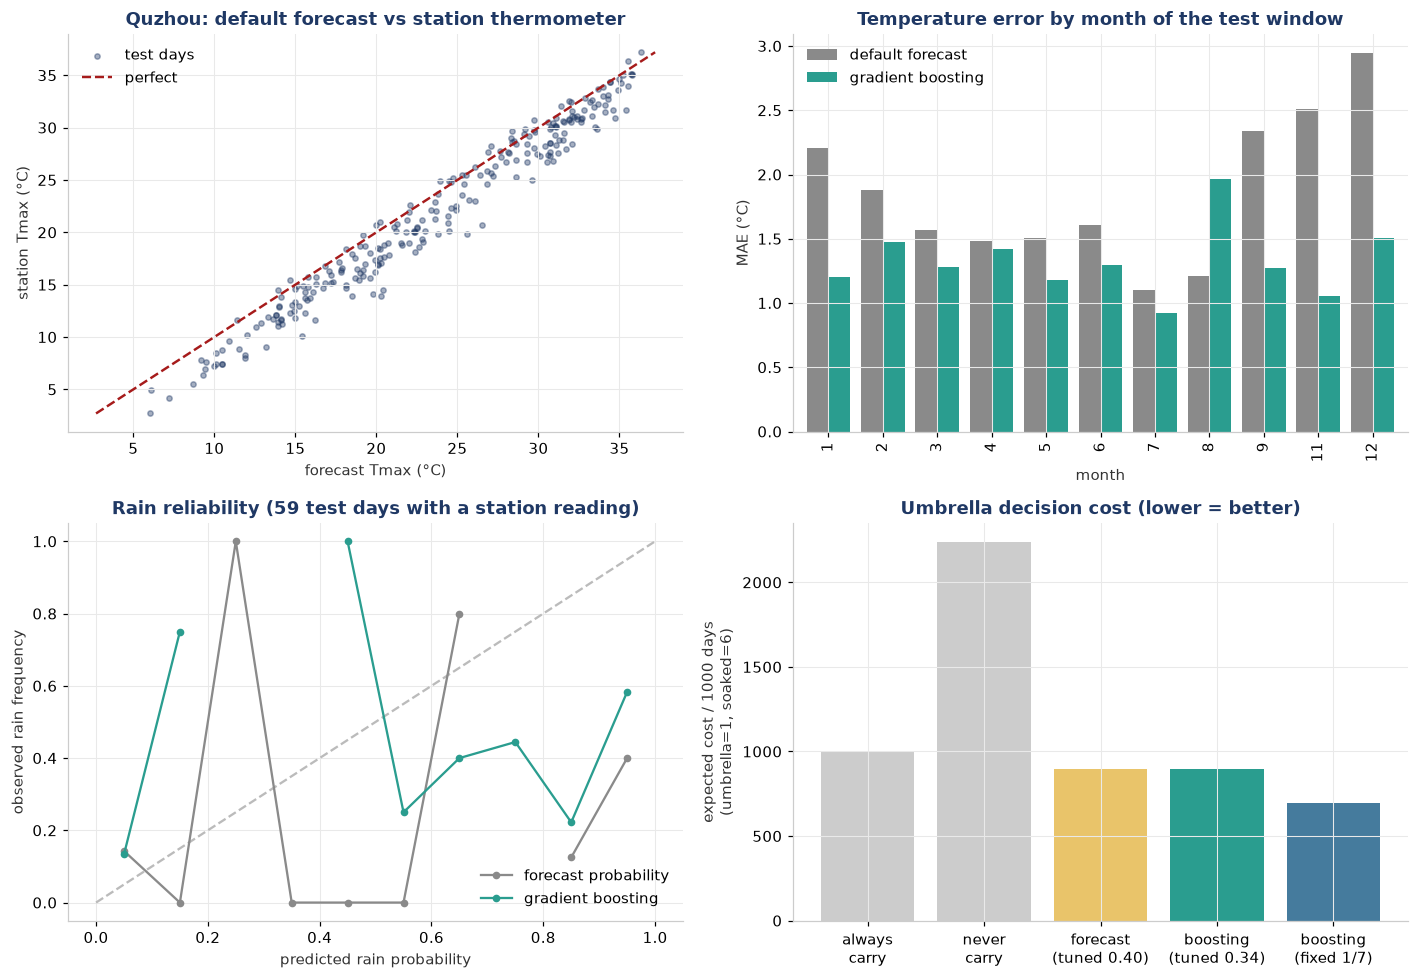

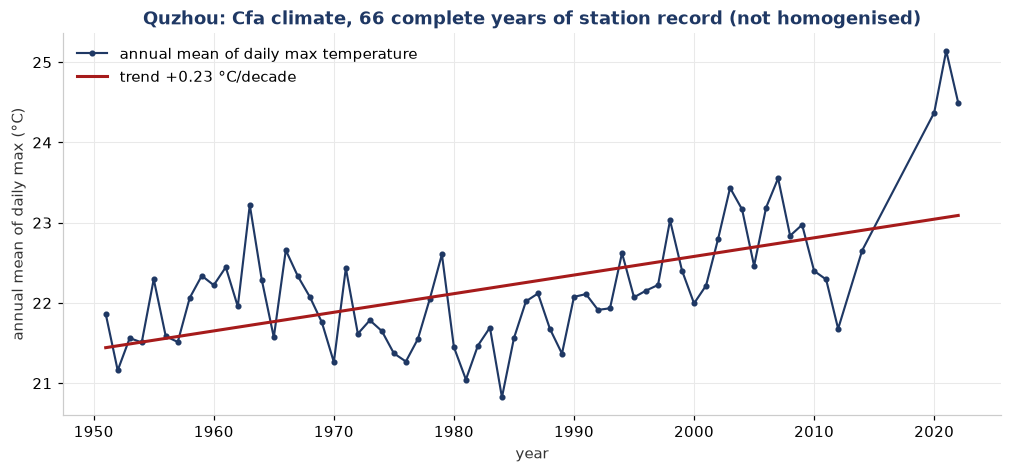

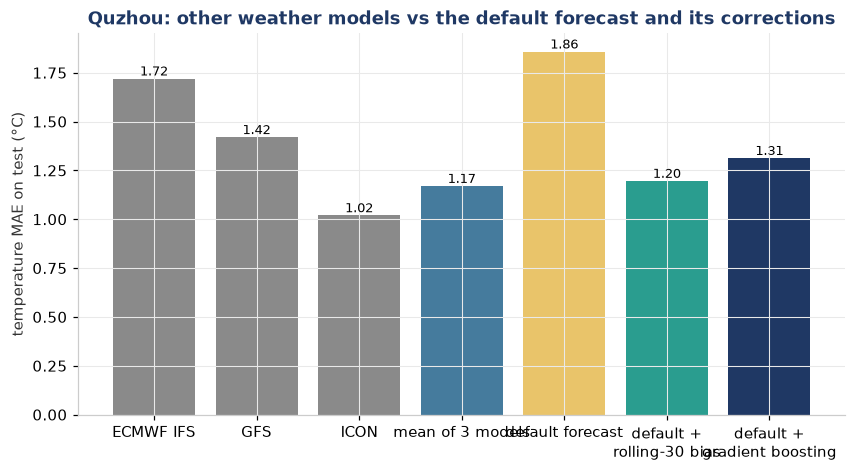

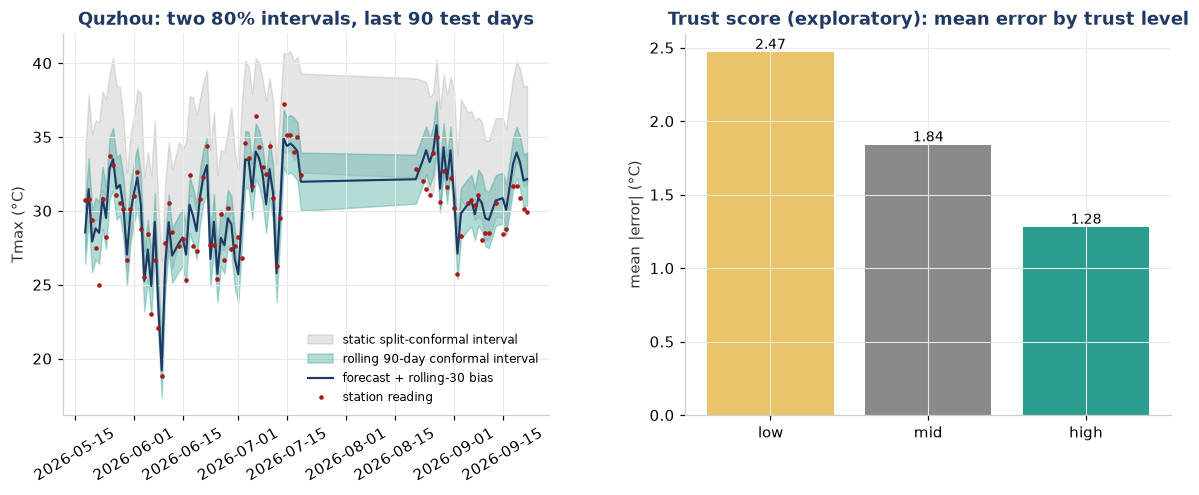

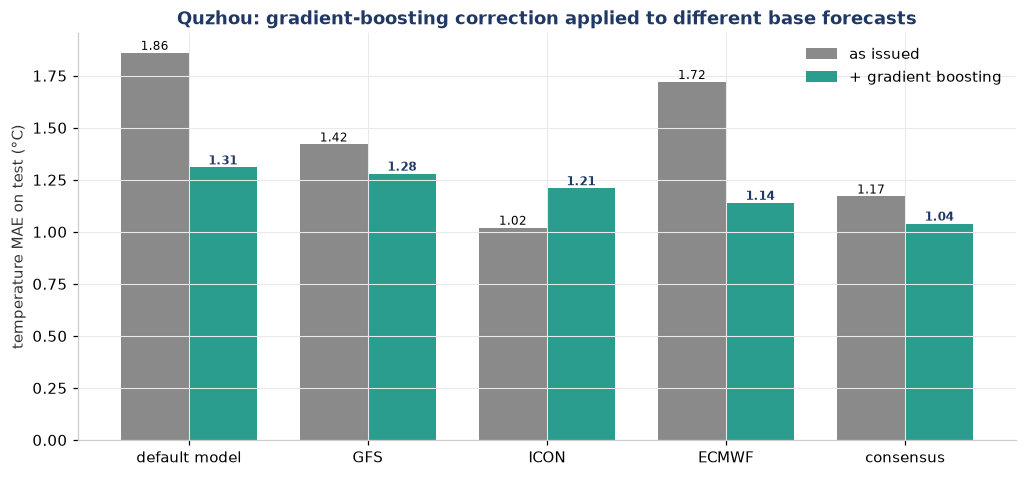

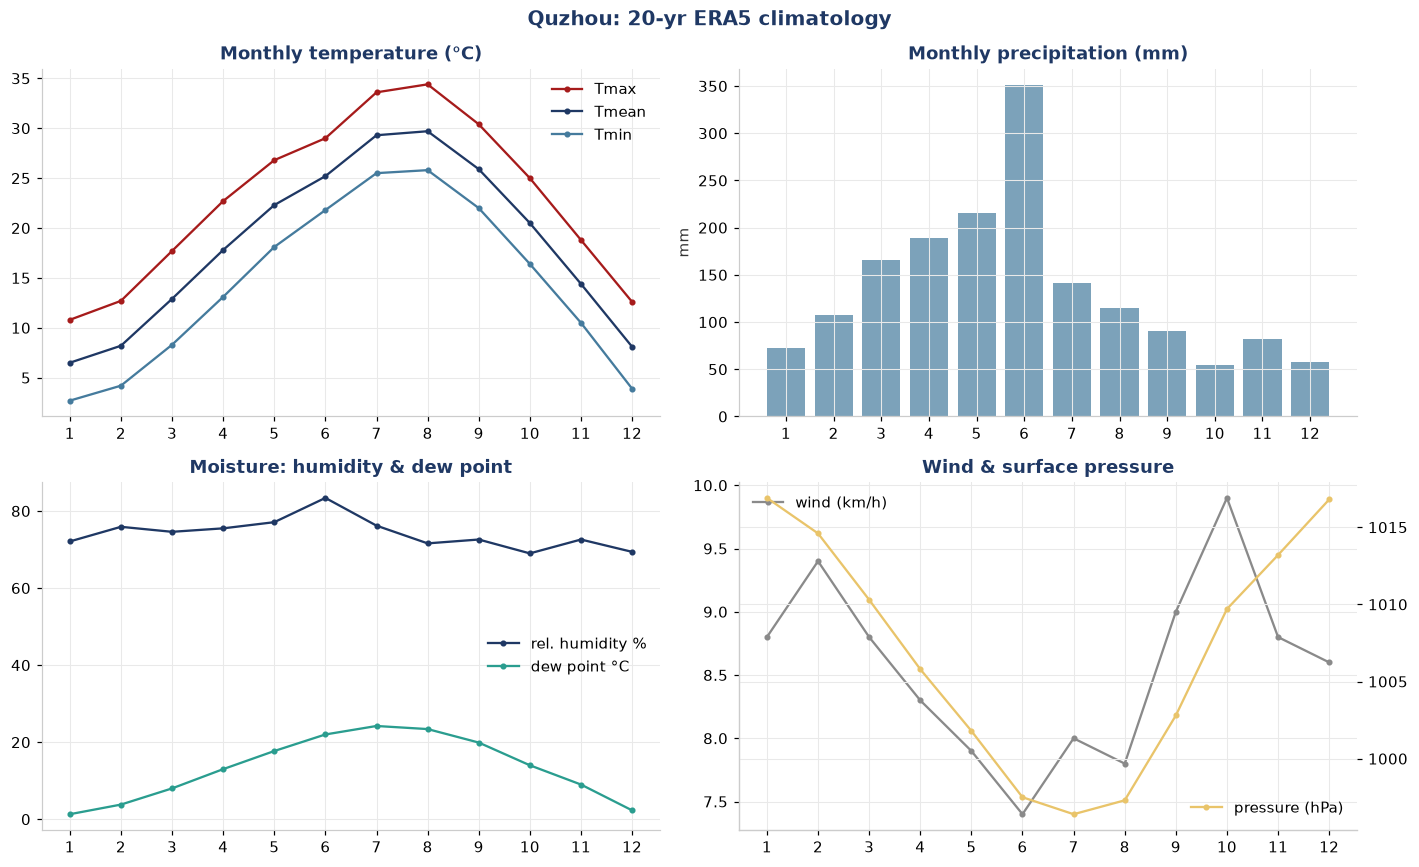

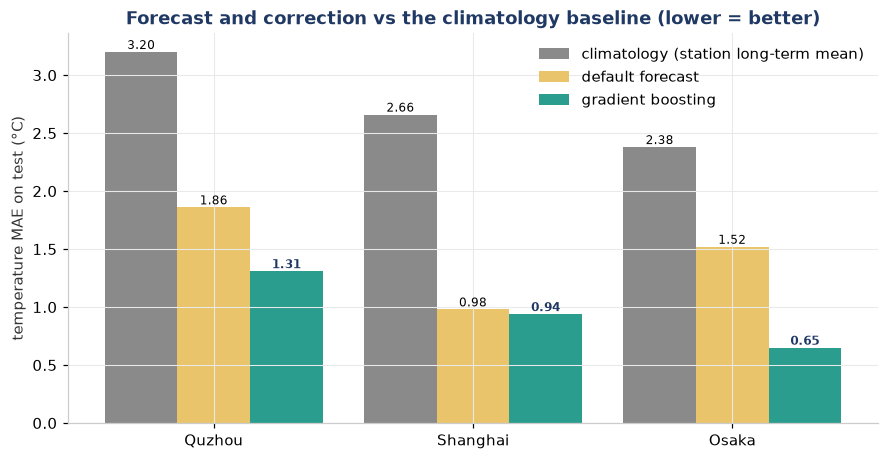

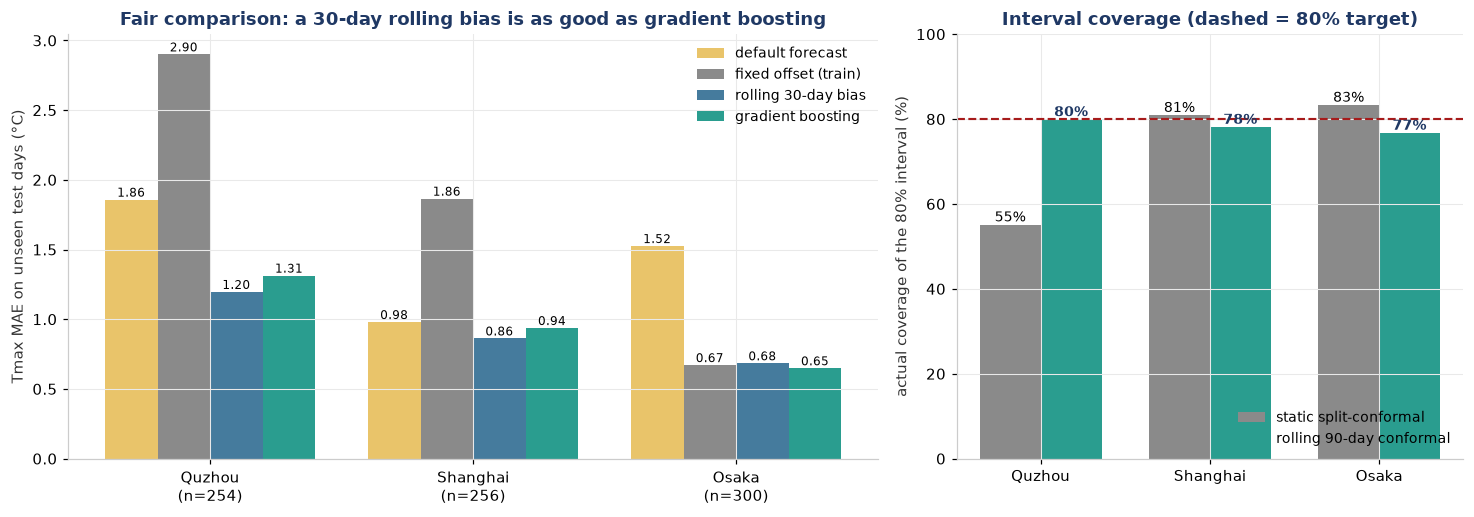

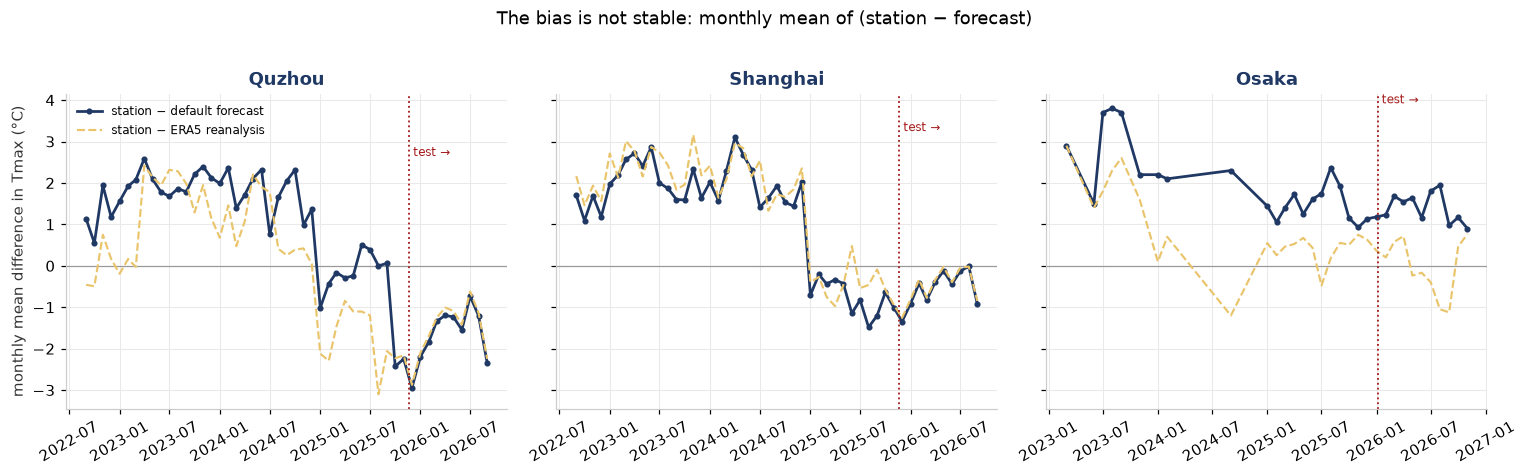

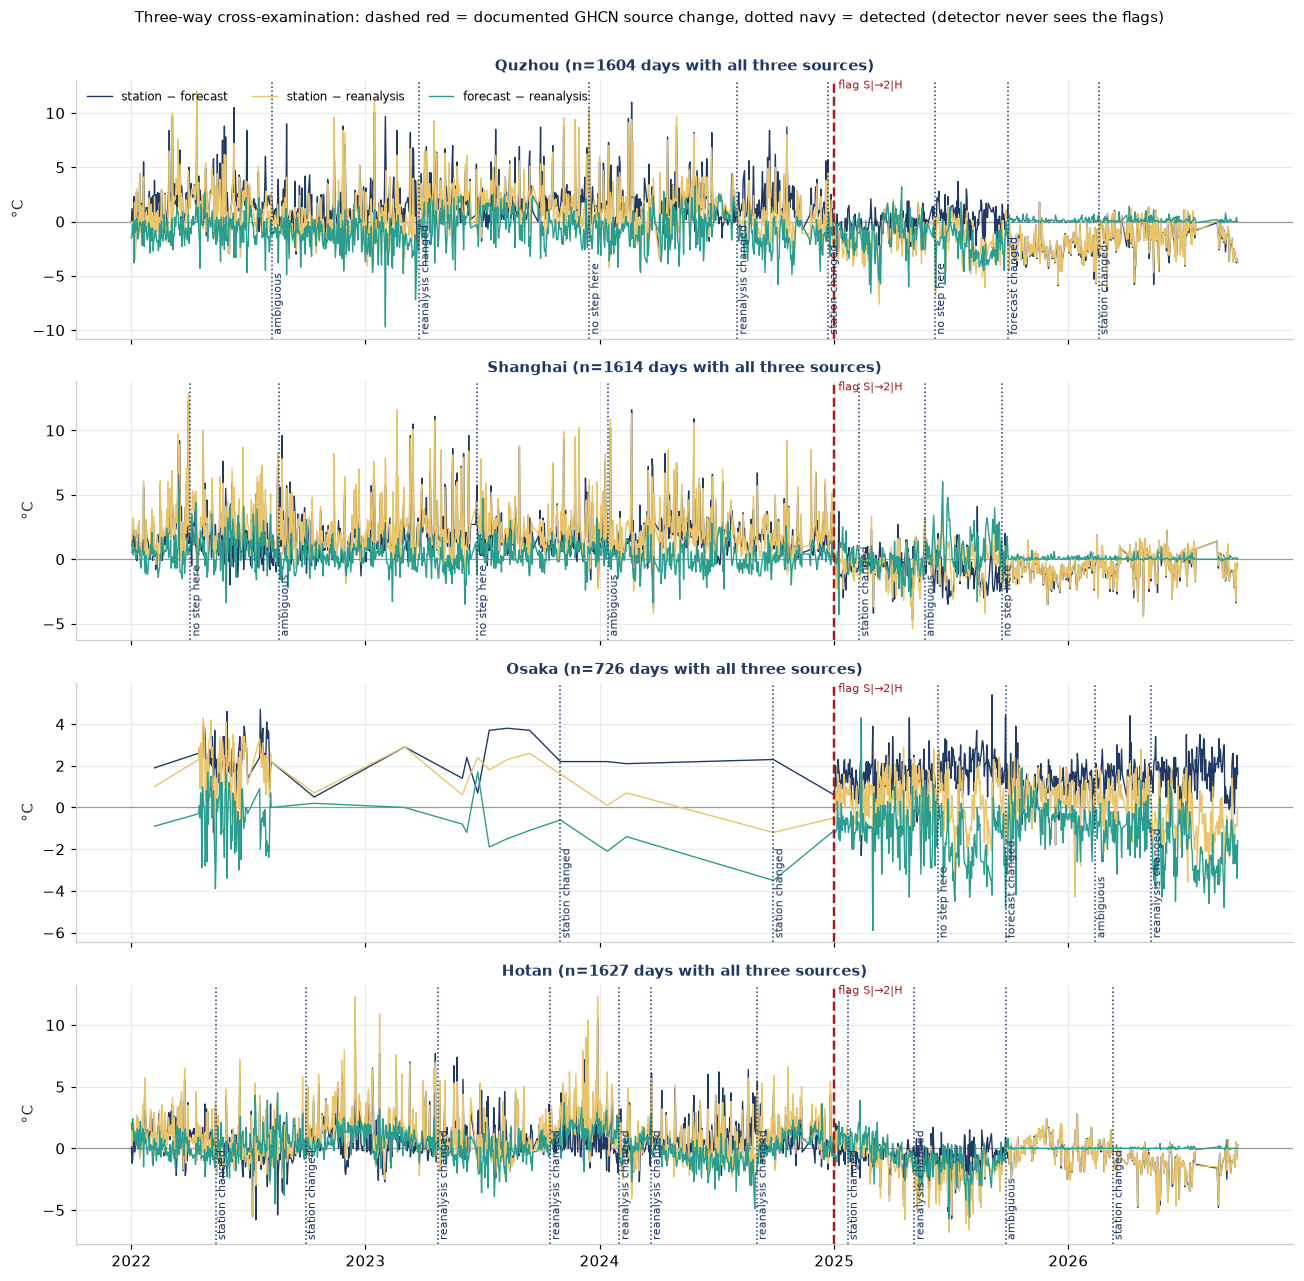

In [15]:
primary = all_res[PRIMARY]
ctx = ctxs[PRIMARY]
te, re_ = ctx["temp"], ctx["rain"]
te4 = ctx.get("te4", te)
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

ax = axes[0][0]
ax.scatter(te.fc_tmax, te.s_tmax, s=12, alpha=0.4, color=NAVY, label="test days")
lo_, hi_ = min(te.fc_tmax.min(), te.s_tmax.min()), max(te.fc_tmax.max(), te.s_tmax.max())
ax.plot([lo_, hi_], [lo_, hi_], "--", color=RED, lw=1.6, label="perfect")
ax.set_xlabel("forecast Tmax (°C)"); ax.set_ylabel("station Tmax (°C)")
ax.set_title(f"{PRIMARY}: default forecast vs station thermometer")
ax.legend(frameon=False)

ax = axes[0][1]
te2 = te.copy(); te2["month"] = te2.date.dt.month
mm = te2.groupby("month").agg(raw=("s_tmax", lambda s: (s - te2.loc[s.index, "fc_tmax"]).abs().mean()),
                              gb=("s_tmax", lambda s: (s - ctx["gb_pred"][s.index]).abs().mean()))
mm.plot.bar(ax=ax, color=[GRAY, TEAL], width=0.8)
ax.set_xlabel("month"); ax.set_ylabel("MAE (°C)")
ax.set_title("Temperature error by month of the test window")
ax.legend(["default forecast", "gradient boosting"], frameon=False)

ax = axes[1][0]
ax.plot([0, 1], [0, 1], "--", color="#bbbbbb")
for p, lab, col in [(ctx["p_raw"], "forecast probability", GRAY), (ctx["p_gb"], "gradient boosting", TEAL)]:
    bins = np.arange(0, 1.0001, 0.1)
    idx = np.digitize(p, bins) - 1
    obs = pd.Series(re_.y.values).groupby(idx).mean()
    ax.plot(bins[:-1] + 0.05, [obs.get(i, np.nan) for i in range(10)], "-o", color=col, label=lab, ms=4)
ax.set_xlabel("predicted rain probability"); ax.set_ylabel("observed rain frequency")
ax.set_title(f"Rain reliability ({len(re_)} test days with a station reading)")
ax.legend(frameon=False)

ax = axes[1][1]
labels = ["always\ncarry", "never\ncarry", f"forecast\n(tuned {ctx['th_raw']:.2f})", f"boosting\n(tuned {ctx['th_gb']:.2f})", "boosting\n(fixed 1/7)"]
vals = [1000, re_.y.mean() * C_RAIN * 1000, ctx["cost_raw"], ctx["cost_gb"], ctx["cost_gb_cal"]]
cols = ["#cccccc", "#cccccc", AMBER, TEAL, BLUE]
ax.bar(labels, vals, color=cols)
ax.set_ylabel("expected cost / 1000 days\n(umbrella=1, soaked=6)")
ax.set_title("Umbrella decision cost (lower = better)")
plt.tight_layout()
fig.savefig("weather_audit.png", dpi=150)
print("figure saved: weather_audit.png")

# ---- climate figure (primary city) ----
st = fetch_station(STATIONS[PRIMARY][0])
tmean = _annual_mean(st["TMAX"])
fig2, ax2 = plt.subplots(figsize=(11, 4.5))
ax2.plot(tmean.index.year, tmean.values, "o-", color=NAVY, ms=3, lw=1.4, label="annual mean of daily max temperature")
x = tmean.index.year.values.astype(float)
slope, intercept, *_ = linregress(x, tmean.values)
ax2.plot(x, intercept + slope * x, "-", color=RED, lw=2, label=f"trend {slope*10:+.2f} °C/decade")
ax2.set_xlabel("year"); ax2.set_ylabel("annual mean of daily max (°C)")
ax2.set_title(f"{PRIMARY}: {climate[PRIMARY]['koppen']['code']} climate, {len(tmean)} complete years of station record (not homogenised)")
ax2.legend(frameon=False)
fig2.savefig("weather_climate.png", dpi=150)
print("figure saved: weather_climate.png")

# ---- multi-model figure ----
fig3, ax3 = plt.subplots(figsize=(9, 4.5))
mmod = mmres[PRIMARY]
labels3, vals3, cols3 = [], [], []
for c in ("ECMWF IFS", "GFS", "ICON"):
    if c in mmod.get("per_model", {}):
        labels3.append(c); vals3.append(mmod["per_model"][c]["mae"]); cols3.append(GRAY)
labels3 += ["mean of 3 models", "default forecast", "default +\nrolling-30 bias", "default +\ngradient boosting"]
vals3 += [mmod.get("consensus_mae"), fair[PRIMARY]["mae"]["raw"], fair[PRIMARY]["mae"]["roll30"], fair[PRIMARY]["mae"]["gbm"]]
cols3 += [BLUE, AMBER, TEAL, NAVY]
ax3.bar(labels3, vals3, color=cols3)
ax3.set_ylabel("temperature MAE on test (°C)")
ax3.set_title(f"{PRIMARY}: other weather models vs the default forecast and its corrections")
for i, v in enumerate(vals3):
    ax3.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8.5)
fig3.savefig("weather_multimodel.png", dpi=150)
print("figure saved: weather_multimodel.png")

# ---- uncertainty + credibility figure ----
fig4, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.5))
te4 = te4.sort_values("date")
tail = te4.tail(90)
a1.fill_between(tail.date, tail.cf_lo, tail.cf_hi, color=GRAY, alpha=0.22, label="static split-conformal interval")
a1.fill_between(tail.date, tail.ad_lo, tail.ad_hi, color=TEAL, alpha=0.35, label=f"rolling {AD_WIN}-day conformal interval")
a1.plot(tail.date, tail.r30_pred, color=NAVY, lw=1.4, label="forecast + rolling-30 bias")
a1.plot(tail.date, tail.s_tmax, ".", color=RED, ms=4, label="station reading")
a1.set_title(f"{PRIMARY}: two 80% intervals, last 90 test days")
a1.legend(frameon=False, fontsize=8); a1.set_ylabel("Tmax (°C)")
a1.tick_params(axis="x", rotation=30)

order = ["low", "mid", "high"]
vals_cred = [cred[PRIMARY]["bins"][k] for k in order]
a2.bar(order, vals_cred, color=[AMBER, GRAY, TEAL])
for i, v in enumerate(vals_cred):
    a2.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
a2.set_title("Trust score (exploratory): mean error by trust level")
a2.set_ylabel("mean |error| (°C)")
fig4.subplots_adjust(wspace=0.28)
fig4.savefig("weather_uncertainty.png", dpi=150)
print("figure saved: weather_uncertainty.png")

# ---- smart base ladder (primary city) ----
sb = smart[PRIMARY]
if sb:
    labels5 = [k for k in ("default model", "GFS", "ICON", "ECMWF", "consensus") if sb.get(k)]
    fig5, ax5 = plt.subplots(figsize=(11, 4.8))
    x = np.arange(len(labels5)); w = 0.38
    rawv = [sb[k]["raw"] for k in labels5]
    corrv = [sb[k]["corr"] for k in labels5]
    ax5.bar(x - w / 2, rawv, w, color=GRAY, label="as issued")
    ax5.bar(x + w / 2, corrv, w, color=TEAL, label="+ gradient boosting")
    for i, (r, c) in enumerate(zip(rawv, corrv)):
        ax5.text(i - w / 2, r, f"{r:.2f}", ha="center", va="bottom", fontsize=8)
        ax5.text(i + w / 2, c, f"{c:.2f}", ha="center", va="bottom", fontsize=8, color=NAVY, fontweight="bold")
    ax5.set_xticks(x); ax5.set_xticklabels(labels5)
    ax5.set_ylabel("temperature MAE on test (°C)")
    ax5.set_title(f"{PRIMARY}: gradient-boosting correction applied to different base forecasts")
    ax5.legend(frameon=False)
    fig5.savefig("weather_smartbase.png", dpi=150)
    print("figure saved: weather_smartbase.png")

# ---- climate profile (primary city, multi-element monthly climatology) ----
cp = climprof[PRIMARY]
if cp:
    m = cp["monthly"]
    fig6, ((a1, a2), (a3, a4)) = plt.subplots(2, 2, figsize=(13, 8))
    xm = np.arange(1, 13)
    a1.plot(xm, m.t_max, "-o", color=RED, ms=3, label="Tmax")
    a1.plot(xm, m.t_mean, "-o", color=NAVY, ms=3, label="Tmean")
    a1.plot(xm, m.t_min, "-o", color=BLUE, ms=3, label="Tmin")
    a1.set_xticks(xm); a1.set_title("Monthly temperature (°C)"); a1.legend(frameon=False)
    a2.bar(xm, m.precip, color=BLUE, alpha=0.7)
    a2.set_xticks(xm); a2.set_title("Monthly precipitation (mm)"); a2.set_ylabel("mm")
    a3.plot(xm, m.rh, "-o", color=NAVY, ms=3, label="rel. humidity %")
    a3.plot(xm, m.dew, "-o", color=TEAL, ms=3, label="dew point °C")
    a3.set_xticks(xm); a3.set_title("Moisture: humidity & dew point"); a3.legend(frameon=False)
    a4.plot(xm, m.wind, "-o", color=GRAY, ms=3, label="wind (km/h)")
    a4b = a4.twinx(); a4b.plot(xm, m.pressure, "-o", color=AMBER, ms=3, label="pressure (hPa)")
    a4.set_xticks(xm); a4.set_title("Wind & surface pressure")
    a4.legend(loc="upper left", frameon=False); a4b.legend(loc="lower right", frameon=False)
    fig6.suptitle(f"{PRIMARY}: {cp['ann']['n_years']}-yr ERA5 climatology", fontsize=13, color=NAVY, fontweight="bold")
    fig6.tight_layout()
    fig6.savefig("weather_climate_profile.png", dpi=150)
    print("figure saved: weather_climate_profile.png")

# ---- climatology skill (forecast / correction vs climatology baseline) ----
if clskill and clskill[PRIMARY]:
    fig7, ax7 = plt.subplots(figsize=(9.5, 4.6))
    names7 = list(clskill.keys())
    x7 = np.arange(len(names7)); w7 = 0.28
    climv = [clskill[n]["mae_clim"] for n in names7]
    rawv = [clskill[n]["mae_raw"] for n in names7]
    gbv = [clskill[n]["mae_gb"] for n in names7]
    ax7.bar(x7 - w7, climv, w7, color=GRAY, label="climatology (station long-term mean)")
    ax7.bar(x7, rawv, w7, color=AMBER, label="default forecast")
    ax7.bar(x7 + w7, gbv, w7, color=TEAL, label="gradient boosting")
    for i, (c, r, g) in enumerate(zip(climv, rawv, gbv)):
        ax7.text(i - w7, c, f"{c:.2f}", ha="center", va="bottom", fontsize=8)
        ax7.text(i, r, f"{r:.2f}", ha="center", va="bottom", fontsize=8)
        ax7.text(i + w7, g, f"{g:.2f}", ha="center", va="bottom", fontsize=8, color=NAVY, fontweight="bold")
    ax7.set_xticks(x7); ax7.set_xticklabels(names7)
    ax7.set_ylabel("temperature MAE on test (°C)")
    ax7.set_title("Forecast and correction vs the climatology baseline (lower = better)")
    ax7.legend(frameon=False)
    fig7.savefig("weather_skill.png", dpi=150)
    print("figure saved: weather_skill.png")

# ---- fair baselines + adaptive interval ----
fig8, (axa, axb) = plt.subplots(1, 2, figsize=(13.5, 4.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
names8 = list(fair.keys()); x8 = np.arange(len(names8)); w8 = 0.2
series = [("raw", "default forecast", AMBER), ("const_bias", "fixed offset (train)", GRAY),
          ("roll30", "rolling 30-day bias", BLUE), ("gbm", "gradient boosting", TEAL)]
for j, (key, lab, col) in enumerate(series):
    vals = [fair[n]["mae"][key] for n in names8]
    axa.bar(x8 + (j - 1.5) * w8, vals, w8, color=col, label=lab)
    for i, v in enumerate(vals):
        axa.text(i + (j - 1.5) * w8, v, f"{v:.2f}", ha="center", va="bottom", fontsize=8)
axa.set_xticks(x8); axa.set_xticklabels([f"{n}\n(n={fair[n]['n']})" for n in names8])
axa.set_ylabel("Tmax MAE on unseen test days (°C)")
axa.set_title("Fair comparison: a 30-day rolling bias is as good as gradient boosting")
axa.legend(frameon=False, fontsize=9)
old = [conf[n]["split_conformal"]["coverage"] * 100 for n in names8]
new = [adapt[n]["coverage"] * 100 for n in names8]
axb.bar(x8 - 0.18, old, 0.36, color=GRAY, label="static split-conformal")
axb.bar(x8 + 0.18, new, 0.36, color=TEAL, label=f"rolling {AD_WIN}-day conformal")
for i, (o, nw) in enumerate(zip(old, new)):
    axb.text(i - 0.18, o, f"{o:.0f}%", ha="center", va="bottom", fontsize=9)
    axb.text(i + 0.18, nw, f"{nw:.0f}%", ha="center", va="bottom", fontsize=9, color=NAVY, fontweight="bold")
axb.axhline(CONF_LEVEL * 100, ls="--", color=RED, lw=1.4)
axb.set_xticks(x8); axb.set_xticklabels(names8); axb.set_ylim(0, 100)
axb.set_ylabel("actual coverage of the 80% interval (%)")
axb.set_title("Interval coverage (dashed = 80% target)")
axb.legend(frameon=False, fontsize=9, loc="lower right")
fig8.tight_layout()
fig8.savefig("weather_fair.png", dpi=150)
print("figure saved: weather_fair.png")

# ---- bias drift timeline ----
fig9, axes9 = plt.subplots(1, len(drift_tl), figsize=(14, 4.2), sharey=True)
for ax9, nm in zip(np.atleast_1d(axes9), drift_tl):
    tl = drift_tl[nm]; xs = tl.index.to_timestamp()
    ax9.axhline(0, color="#999", lw=0.8)
    ax9.plot(xs, tl.station_minus_forecast, color=NAVY, lw=1.8, marker="o", ms=3, label="station − default forecast")
    ax9.plot(xs, tl.station_minus_era5, color=AMBER, lw=1.4, ls="--", label="station − ERA5 reanalysis")
    ax9.axvline(ctxs[nm]["ts"], color=RED, lw=1.2, ls=":")
    ax9.text(ctxs[nm]["ts"], ax9.get_ylim()[1], " test →", color=RED, fontsize=8, va="top")
    ax9.set_title(nm); ax9.tick_params(axis="x", rotation=30)
np.atleast_1d(axes9)[0].set_ylabel("monthly mean difference in Tmax (°C)")
np.atleast_1d(axes9)[0].legend(frameon=False, fontsize=8, loc="upper left")
fig9.suptitle("The bias is not stable: monthly mean of (station − forecast)", y=1.02)
fig9.tight_layout()
fig9.savefig("weather_drift.png", dpi=150, bbox_inches="tight")
print("figure saved: weather_drift.png")

# ---- three-way cross-examination ----
xe_plot = [nm for nm in xe if xe[nm]["events"]] or list(xe)
fig10, axes10 = plt.subplots(len(xe_plot), 1, figsize=(12, 2.9 * len(xe_plot)), sharex=True)
for ax10, nm in zip(np.atleast_1d(axes10), xe_plot):
    d = xe[nm]["series"]
    xs = np.array(d["days"], dtype="datetime64[D]")
    ax10.axhline(0, color="#999", lw=0.8)
    ax10.plot(xs, d["sf"], color=NAVY, lw=0.9, label="station − forecast")
    ax10.plot(xs, d["se"], color=AMBER, lw=0.9, label="station − reanalysis")
    ax10.plot(xs, d["fe"], color=TEAL, lw=0.9, label="forecast − reanalysis")
    for r in xe[nm]["answer_key"]:
        ax10.axvline(np.datetime64(r["switch"]), color=RED, lw=1.6, ls="--")
        ax10.text(np.datetime64(r["switch"]), ax10.get_ylim()[1],
                  f" flag {r['flag_from']}→{r['flag_to']}", color=RED, fontsize=7, va="top")
    for e in xe[nm]["events"]:
        ax10.axvline(np.datetime64(e["date"]), color=NAVY, lw=1.0, ls=":")
        ax10.text(np.datetime64(e["date"]), ax10.get_ylim()[0],
                  f" {e['verdict']}", color=NAVY, fontsize=7, va="bottom", rotation=90)
    ax10.set_title(f"{nm} (n={xe[nm]['n_days']} days with all three sources)", fontsize=10)
    ax10.set_ylabel("°C")
np.atleast_1d(axes10)[0].legend(frameon=False, fontsize=8, ncol=3, loc="upper left")
fig10.suptitle("Three-way cross-examination: dashed red = documented GHCN source change, "
               "dotted navy = detected (detector never sees the flags)", y=1.0, fontsize=10)
fig10.tight_layout()
fig10.savefig("weather_crossexam.png", dpi=150, bbox_inches="tight")
print("figure saved: weather_crossexam.png")

In [16]:
def _html_report():
    clim = climate[PRIMARY]
    k = clim["koppen"]; tt = clim["trend_tmax"]
    c = conf[PRIMARY]; cd = cred[PRIMARY]; mm = mmres[PRIMARY]
    ad = adapt[PRIMARY]
    last = te4.dropna(subset=["ad_lo", "consensus"]).sort_values("date").iloc[-1]
    inside = last.ad_lo <= last.s_tmax <= last.ad_hi
    return f"""<!DOCTYPE html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>WeatherAudit — {PRIMARY} forecast card</title><style>
:root {{ --navy:#1F3864; --teal:#2a9d8f; --amber:#e9c46a; --red:#a61b1b; --line:#e6e9ef; --bg:#f6f8fb; }}
* {{ box-sizing:border-box; }}
body {{ font-family:-apple-system,Segoe UI,Roboto,Helvetica,Arial,sans-serif; background:var(--bg); color:#1c2733; margin:0; padding:24px; }}
.wrap {{ max-width:640px; margin:0 auto; }}
h1 {{ font-size:20px; color:var(--navy); margin:0 0 2px; }}
.sub {{ color:#6a7a8c; font-size:12.5px; margin-bottom:18px; }}
.card {{ background:#fff; border:1px solid var(--line); border-radius:14px; padding:20px; box-shadow:0 1px 3px rgba(20,40,80,.06); }}
.row {{ display:flex; justify-content:space-between; align-items:baseline; padding:9px 0; border-bottom:1px solid var(--line); }}
.row:last-child {{ border-bottom:none; }}
.k {{ color:#6a7a8c; font-size:13px; }}
.v {{ font-size:15px; font-weight:600; color:var(--navy); }}
.v.hl {{ font-size:26px; color:var(--teal); }}
.v.warn {{ color:var(--amber); }}
.badge {{ display:inline-block; padding:3px 10px; border-radius:999px; font-size:12px; font-weight:700; }}
.badge.high {{ background:#e3f4f0; color:var(--teal); }}
.badge.mid {{ background:#f0f1f4; color:#5a6a7a; }}
.badge.low {{ background:#fdf0e4; color:#b0761c; }}
.grid {{ display:grid; grid-template-columns:1fr 1fr; gap:12px; margin-top:16px; }}
.tile {{ background:#fff; border:1px solid var(--line); border-radius:12px; padding:14px; }}
.tile h3 {{ font-size:11px; letter-spacing:.04em; text-transform:uppercase; color:#8a97a5; margin:0 0 6px; }}
.tile .big {{ font-size:20px; font-weight:700; color:var(--navy); }}
.tile .note {{ font-size:11.5px; color:#6a7a8c; margin-top:3px; line-height:1.4; }}
.foot {{ font-size:11px; color:#8a97a5; margin-top:16px; line-height:1.5; }}
</style></head><body><div class="wrap">
<h1>WeatherAudit · forecast card (historical replay of {last.date:%Y-%m-%d})</h1>
<div class="sub">{PRIMARY} (GHCN {STATIONS[PRIMARY][0]}) · {k['code']} climate · replay of a past day, built only from data available 8+ days earlier · prototype, not a weather service</div>
<div class="card">
  <div class="row"><span class="k">Default model forecast (Tmax)</span><span class="v">{last.fc_tmax:.1f} °C</span></div>
  <div class="row"><span class="k">Mean of {last.n_models:.0f} weather models</span><span class="v">{last.consensus:.1f} °C</span></div>
  <div class="row"><span class="k">Corrected (30-day rolling bias)</span><span class="v hl">{last.r30_pred:.1f} °C</span></div>
  <div class="row"><span class="k">80% interval (rolling conformal)</span><span class="v">{last.ad_lo:.1f} – {last.ad_hi:.1f} °C</span></div>
  <div class="row"><span class="k">Trust score</span><span class="v warn">{last.trust:.0f}/100</span></div>
  <div class="row"><span class="k">What the station then measured</span><span class="v">{last.s_tmax:.1f} °C ({'inside' if inside else 'outside'} the interval)</span></div>
</div>
<div class="grid">
  <div class="tile"><h3>Model agreement</h3><div class="big">{last.n_models:.0f} models</div><div class="note">spread today: {last.spread:.2f} °C</div></div>
  <div class="tile"><h3>Long-term trend</h3><div class="big">{tt.get('slope_decade', 0):+.2f} °C/decade</div><div class="note">{tt.get('years', 0)} years, {tt.get('first_year', '')}–{tt.get('last_year', '')}</div></div>
  <div class="tile"><h3>Interval coverage</h3><div class="big">{ad['coverage']*100:.0f}%</div><div class="note">target {int(CONF_LEVEL*100)}%, over {ad['n']} test days (a static interval only reached {c['split_conformal']['coverage']*100:.0f}%)</div></div>
  <div class="tile"><h3>Trust audit</h3><div class="big">{'passes' if cd['monotonic'] else 'mixed'}</div><div class="note">low-trust days err {cd['bins']['low']}°C vs high-trust {cd['bins']['high']}°C</div></div>
</div>
<div class="foot">This card replays the most recent audited day; it is not a live forecast. The correction removes the forecast's mean error over a 30-day window that ends 8 days earlier; the interval is the 80th percentile of the recent absolute errors. The trust score combines model agreement with the forecast's recent accuracy. Prototype — not for safety-critical decisions.</div>
</div></body></html>"""
html = _html_report()
with open("weather_report.html", "w", encoding="utf-8") as fh:
    fh.write(html)
print("html saved: weather_report.html")

climprof_ser = {
    nm: dict(ann=cp["ann"],
             monthly=[dict(month=int(k), **{c: float(v) for c, v in row.items()})
                      for k, row in cp["monthly"].iterrows()])
    for nm, cp in climprof.items() if cp
}
xe_ser = {nm: {k: v for k, v in d.items() if k != "series"} for nm, d in xe.items()}
out = dict(primary=PRIMARY,
           params=dict(TEST_DAYS=TEST_DAYS, N_EST=N_EST, C_UMB=C_UMB, C_RAIN=C_RAIN,
                       RAIN_MM=RAIN_MM, CONF_LEVEL=CONF_LEVEL, MODELS=MODELS,
                       N_BOOT=N_BOOT, BLOCK=BLOCK, AD_WIN=AD_WIN, N_SEEDS=N_SEEDS,
                       XE_JUMP_MIN=XE_JUMP_MIN, XE_T_MIN=XE_T_MIN, XE_MIN_SEG=XE_MIN_SEG,
                       XE_LOCAL_WIN=XE_LOCAL_WIN, XE_N_PERM=XE_N_PERM, XE_TOL_DAYS=XE_TOL_DAYS),
           cities=all_res, climate=climate, multimodel=mmres,
           conformal=conf, credibility=cred, smartbase=smart,
           climprof=climprof_ser, clskill=clskill,
           fair=fair, adaptive_interval=adapt, drift=drift, lead_time=lead,
           crossexam=xe_ser,
           drift_monthly={nm: {str(k): {c: (None if pd.isna(v) else round(float(v), 2)) for c, v in row.items()}
                               for k, row in tl.iterrows()} for nm, tl in drift_tl.items()})
with open("results_v4.json", "w", encoding="utf-8") as fh:
    json.dump(out, fh, ensure_ascii=False, indent=2, default=str)
print("results saved: results_v4.json")

display(HTML(html))

html saved: weather_report.html
results saved: results_v4.json


## 6. Limitations

* **A station is one point, and not the author's doorstep.** Quzhou is the nearest GHCN station with recent data to the author's home, about 114 km away.
* **We now know which source moved, but not why it was changed.** The cross-examination blames the station record, and the GHCN flags confirm the provenance changed on 2025-01-01 from a daily summary to values derived from hourly readings. Why the feed changed, and whether the thermometer or only the bookkeeping moved, is outside what these three series can show.
* **The three sources are not fully independent.** The forecast and the reanalysis are both output from numerical weather models, so a change shared by both would not stand out the way a station change does.
* **The detector is blind to small steps.** Planted 0.5 °C steps are found 3 times in 9 and attributed once; a step has to be around 2 °C before attribution is reliable (Table 10).
* **Its false-alarm rate is not zero.** With nothing planted, the same three windows still return 12 events (Table 11). A verdict is a reason to go and check a data source, not proof on its own.
* **Four stations, and three of them in China.** The dates it finds also land 10 to 39 days from the documented switch, not on it.
* **The archived forecast is not what a phone app showed.** It is a single weather model's output, stitched from short lead times (see Table 3).
* **Small samples.** Rain is tested on 56 to 129 days from one summer and autumn. Quzhou has 2 hot days. Osaka's training set is only about one year because of a gap in its temperature record.
* **Different test periods.** Osaka's window ends later than the Chinese ones, so the cities are not compared on identical days.
* **In Quzhou a different model was better than anything we did.** Raw ICON has an error of 1.02 °C there, below our corrected 1.20 °C (Table 7). Choosing the model matters as much as correcting it.
* **The trust score and the climate trend are context, not results.** The score's bins were cut on test-period values, and the trends come from single stations that have not been homogenised.
* **Only daily maximum temperature and rain / no rain** were audited.

## 7. Sources

* NOAA GHCN-Daily station data: https://registry.opendata.aws/noaa-ghcn/ (stations CHM00058633 Quzhou, CHM00058362 Shanghai, JAM00047772 Osaka, CHM00051828 Hotan)
* GHCN-Daily flag definitions (the answer key): the `ghcnd-readme.txt` shipped with the dataset, sections on S_FLAG and M_FLAG
* Open-Meteo Historical Forecast, Previous Runs and Archive (ERA5) APIs: https://open-meteo.com/ (data licensed CC BY 4.0)
* ERA5: Hersbach et al., Copernicus Climate Change Service
* Conformal prediction: Angelopoulos and Bates, *A Gentle Introduction to Conformal Prediction*, https://arxiv.org/abs/2107.07511
* Libraries: pandas, NumPy, SciPy, scikit-learn, matplotlib, requests
* AI tools: AI coding assistants (Claude and WorkBuddy) were used heavily, to write and debug the code, run the experiments and draft the text. The author chose the question and directed the work.

Every number quoted above is printed by the code in this notebook.